<div align="center" dir="rtl">

<span style="color:#1F7A8C; font-weight:600; letter-spacing:0.5px;">درس پردازش زبان طبیعی</span>

# <span style="color:#1F7A8C;">Tokenization and N-gram LMs</span>



<hr style="border:0; border-top:2px solid #1F7A8C; width:55%; margin:20px auto 24px auto;">

### <span style="color:#1F7A8C;">مشخصات تکلیف</span>

<div style="display:inline-block; text-align:right;">

| مورد | مقدار |
|---:|---:|
| شماره‌ی تکلیف | یک |
| مسئول تکلیف | علیرضا فرشی |
| ایمیل | azerila.farshi@gmail.com |
| تاریخ انتشار | ۲۸ / ۷ / ۱۴۰۵ |
| مهلت تحویل | ۱۰ / ۸ / ۱۴۰۵ |
| مهلت تحویل با تأخیر | ۱۷ / ۸ / ۱۴۰۵ |
| بارم کل | ۱۵۰ نمره |


</div>

### <span style="color:#1F7A8C;">مشخصات دانشجو</span>

<span style="color:#5A6B7B;">این جدول را پیش از ارسال تکمیل کنید.</span>

<div style="display:inline-block; text-align:right;">

| مورد | مقدار |
|---:|---:|
| نام و نام خانوادگی ||
| شماره‌ی دانشجویی |  |

</div>

<hr style="border:0; border-top:2px solid #1F7A8C; width:55%; margin:24px auto 8px auto;">

</div>

<div dir="rtl" align="right">

## مقدمه

در این تکلیف، دو موضوع بنیادی در پردازش زبان طبیعی بررسی می‌شود: **توکن‌سازی** و **مدل‌سازی زبانی با N-gram**. در بخش اول، الگوریتم **Byte Pair Encoding (BPE)** را از صفر پیاده‌سازی می‌کنیم؛ الگوریتمی که در مدل‌های زبانی مدرن مثل GPT-2 تا GPT-4 و Llama 3 استفاده می‌شود. هدف این بخش، درک عمیق نحوه‌ی تبدیل متن به توکن، ساخت واژگان زیرکلمه‌ای و مقایسه با پیاده‌سازی‌های حرفه‌ای است. در بخش دوم، مدل‌های زبانی **N-gram** را از مرتبه‌ی ۱ تا ۴ پیاده‌سازی کرده و تکنیک‌های هموارسازی (Smoothing) و Backoff را برای مقابله با مشکل پراکندگی داده ارزیابی می‌کنیم. در پایان، عملکرد مدل‌ها را با معیار Perplexity مقایسه و از بهترین مدل برای تولید متن استفاده خواهیم کرد.

### اهداف یادگیری

پس از انجام این تکلیف انتظار می‌رود بتوانید:

- الگوریتم BPE را از صفر پیاده‌سازی کرده و مراحل ساخت واژگان، آموزش و رمزگذاری/رمزگشایی را توضیح دهید.
- عملکرد توکنایزر خود را با پیاده‌سازی‌های آماده مثل `tiktoken` و Hugging Face مقایسه و بنچمارک کنید.
- مدل‌های زبانی N-gram را با روش MLE پیاده‌سازی کرده و معیار Perplexity را محاسبه کنید.
- تفاوت روش‌های هموارسازی (Laplace، Linear Interpolation، Stupid Backoff) را در کاهش perplexity تحلیل کنید.

</div>

<div dir="rtl" align="right">

## راهنمای انجام تکلیف

- **گام ۱.** سلول‌های بخش «۰. پیکربندی محیط» را پیش از هر کار دیگری اجرا کنید.
- **گام ۲.** سلول‌های کد دارای نشانه‌ی `WRITE YOUR CODE HERE` را تکمیل کنید. ترتیب و ساختار سلول‌ها را تغییر ندهید و سلولی را حذف نکنید. در صورت نیاز می‌توانید بلافاصله پس از سلول کد هر زیربخش، سلول کد تازه‌ای بیفزایید. کد خود را کامنت‌گذاری کنید و کامنت‌ها را به انگلیسی بنویسید.
- **گام ۳.** در سلول‌های «پاسخ تشریحی»، عبارت `{{پاسخ_خود_را_اینجا_بنویسید}}` را با پاسخ خود جایگزین کنید. پاسخ باید مختصر، مستدل و متکی بر خروجی کدی باشد که خودتان اجرا کرده‌اید.
- **گام ۴.** بخش «جمع‌بندی» و جدول «منابع و ابزارهای کمکی» را تکمیل کنید.
- **گام ۵.** نوت‌بوک را با `Restart & Run All` از ابتدا اجرا کنید و پیش از ذخیره مطمئن شوید خروجی همه‌ی سلول‌ها در فایل باقی مانده است.
- **گام ۶.** چک‌لیست انتهای نوت‌بوک را بررسی و سپس فایل را با نام `NLP_CA{n}_{LASTNAME}_{STUDENTID}.ipynb` ارسال کنید.

متن کامل قوانین در بخش پایانی نوت‌بوک، «قوانین تحویل و صداقت علمی»، آمده است.

</div>

---

<div dir="rtl" align="right">

## ۰. پیکربندی محیط

سلول‌های این بخش را بدون تغییر اجرا کنید. اگر برای پاسخ به سوال‌ها به کتابخانه‌ی دیگری نیاز داشتید، آن را به همین سلول‌ها اضافه کنید تا نوت‌بوک برای مصحح نیز قابل اجرا باشد.

</div>

In [1]:
%pip install tiktoken
%pip install -q kagglehub

In [2]:
# Install the packages required by this assignment.
import pandas as pd
import tiktoken
from transformers import GPT2Tokenizer, GPT2TokenizerFast


In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import kagglehub

In [4]:
# Log in to Hugging Face and download the dataset
from huggingface_hub import notebook_login
from datasets import load_dataset

In [5]:
# Trigger interactive login (requires user to input token)
print("Please enter your Hugging Face token below to log in:")
notebook_login()

Please enter your Hugging Face token below to log in:


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


---

<div dir="rtl" align="right">

## ۱. پیاده‌سازی BPE Tokenizer از صفر

در این بخش، الگوریتم **Byte Pair Encoding (BPE)** را از صفر پیاده‌سازی می‌کنیم. ابتدا دادگان WikiText-2 را بارگذاری کرده و پیش‌پردازش می‌کنیم. سپس یک توکنایزر BPE کامل می‌سازیم که شامل مراحل ساخت واژگان، آموزش (یافتن و ادغام پرتکرارترین جفت‌ها)، رمزگذاری و رمزگشایی متن است. در ادامه، توکنایزر خود را روی داده‌ی test ارزیابی کرده و در نهایت عملکرد آن را با پیاده‌سازی‌های حرفه‌ای مثل `tiktoken` و توکنایزرهای Hugging Face از دو منظر کیفیت خروجی و سرعت اجرا بنچمارک می‌کنیم.

</div>

<div dir="rtl" align="right">

### ۱.۱ آشنایی و بارگذاری دادگان (۵ نمره)

**صورت مسئله**

در این تمرین از دادگان **WikiText-2** برای آموزش توکنایزر استفاده می‌کنیم. این دادگان مجموعه‌ای از مقالات ویکی‌پدیا است که متن آن‌ها تمیز شده و برای کارهای پردازش زبان طبیعی مناسب است. نسخه‌ی خام این دادگان ساختار اصلی متن (نشانه‌گذاری، حروف بزرگ و کوچک، فاصله‌ها) را حفظ می‌کند و به همین دلیل برای آموزش توکنایزر مناسب‌تر است.

**آنچه باید انجام دهید**

- دادگان WikiText-2 را بارگذاری کنید.
- محتوای دادگان را بررسی کنید و بخش train را به‌عنوان پیکره‌ی آموزشی در نظر بگیرید.
- یک نمونه از متن خام را چاپ کنید تا ساختار و ویژگی‌های آن مشخص شود.
- اندازه‌ی تقریبی پیکره (تعداد کاراکترها و خطوط) را گزارش کنید.
- درصد خطوط خالی یا خطوطی که فقط شامل نشانه‌گذاری هستند را محاسبه کنید.
- با نگاه به نمونه‌ی چاپ‌شده، حداقل دو ویژگی ساختاری متن (مثلاً وجود تگ‌های `<unk>`، خطوط عنوان ویکی‌پدیا، یا خطوط شروع‌شده با `=`) را نام ببرید و توضیح دهید هر کدام چه تأثیری روی توکن‌سازی BPE خواهند داشت.

</div>

In [6]:
# Load the dataset after logging in
print("Downloading the dataset mindchain/wikitext2...")
dataset = load_dataset("Salesforce/wikitext", 'wikitext-2-raw-v1')
print("Dataset loaded successfully:", dataset)

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/validation-00000-of-00(…): reconstructing file:   0%|          |  0.00B /  657kB            

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Dataset loaded successfully: DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})


In [7]:
dataset['train']['text']

Column(['', ' = Valkyria Chronicles III = \n', '', ' Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " . \n', " The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustments , such as making the game mor

In [8]:
list(dataset['train']['text'])[4]

" The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustments , such as making the game more forgiving for series newcomers . Character designer Raita Honjou and composer Hitoshi Sakimoto both returned from previous entries , along with Valkyria Chronicles II director Takeshi Ozawa . A large team of writers handled the script . The game 's opening theme was sung by May 'n . \n"

In [9]:
# convert to pandas table
df = pd.DataFrame(list(dataset['train']['text']), columns=['text'])
df

,text
0,
1,= Valkyria Chronicles III = \n
2,
3,Senjō no Valkyria 3 : Unrecorded Chronicles (...
4,"The game began development in 2010 , carrying..."
...,...
36713,Common starlings may be kept as pets or as la...
36714,The common starling 's gift for mimicry has l...
36715,Mozart had a pet common starling which could ...
36716,Common starlings are trapped for food in some...


In [10]:
sum = 0
for i in range(len(df)):
    sum += len(df['text'][i])
print('Total character:', sum)

Total character: 10892990


In [11]:
df['text'].str.strip()

,text
0,
1,= Valkyria Chronicles III =
2,
3,Senjō no Valkyria 3 : Unrecorded Chronicles ( ...
4,"The game began development in 2010 , carrying ..."
...,...
36713,Common starlings may be kept as pets or as lab...
36714,The common starling 's gift for mimicry has lo...
36715,Mozart had a pet common starling which could s...
36716,Common starlings are trapped for food in some ...


In [12]:
# Calculate the percentage of empty or whitespace-only lines
empty_lines = df['text'].str.strip().eq('').sum()
total_lines = len(df)
percentage_empty = (empty_lines / total_lines) * 100

print(f"Total lines: {total_lines}")
print(f"Empty or whitespace-only lines: {empty_lines} ({percentage_empty:.2f}%)")

# Identify structural characteristics
# 1. Count occurrences of <unk> tokens
unk_count = df['text'].str.count('<unk>').sum()
print(f"Total '<unk>' token occurrences: {unk_count}")

# 2. Count lines that start with '=' (headings)
headings_count = df['text'].str.strip().str.startswith('=').sum()
print(f"Total lines starting with '=' (Headings): {headings_count}")

Total lines: 36718
Empty or whitespace-only lines: 12951 (35.27%)
Total '<unk>' token occurrences: 0
Total lines starting with '=' (Headings): 6211


In [13]:
df['text'].str.strip().str.startswith('=')

,text
0,False
1,True
2,False
3,False
4,False
...,...
36713,False
36714,False
36715,False
36716,False


In [14]:
df[df['text'].str.strip().str.startswith('=')]

,text
1,= Valkyria Chronicles III = \n
7,= = Gameplay = = \n
13,= = Plot = = \n
19,= = Development = = \n
24,= = = Music = = = \n
...,...
36687,= = Status = = \n
36692,= = Relationship with humans = = \n
36695,= = = Benefits and problems = = = \n
36703,= = = Control = = = \n


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۱</b>
<br><br>

تعداد کل سطرها برابر ۳۶۷۱۸ بود و تعداد کاراکترهای کل دیتاست آموزش برابر ۱۰۸۹۲۹۹۰ است.

از این تعداد خط، ۳۵ درصد آن‌ها یعنی ۱۲۹۵۱تا خط خالی یا whitespace بودند. و 
۶۲۱۱تا خط با کاراکتر = که احتمالا عنوان آن صفحه در ویکی‌پدیا می‌شود شروع می‌شود.
در دیتاست `<unk>` دیده نشد.

چون تعداد کاراکتر = بسیار زیاد است باعث می‌شود موقع آموزش، کاراکترهای = ادغام شوند و در لیست توکن‌های پرتکرار قرار بگیرند در حالی که ارزشی ندارند.
توکن خاص unk هم پیدا نشد ولی اگر بود به کاراکترهایش تقسیم می‌شد یا ادغام بخشی از کاراکترهایش آن را یاد می‌گرفت. در حالی که کل unk باید به عنوان یک توکن خاص در نظر گرفته شود


</div>

<div dir="rtl" align="right">

### ۱.۲ پیش‌پردازش داده (۱۰ نمره)

**صورت مسئله**

متن خام WikiText-2، مثل هر پیکره‌ی متنی خام دیگری، ممکن است شامل ناهمگونی‌هایی مثل نوع‌های مختلف خط جدید، فاصله‌های تکراری، یا کاراکترهای اضافی باشد. اگر این ناهمگونی‌ها پیش از توکن‌سازی پاک نشوند، توکن‌های تکراری و بی‌معنا در واژگان ساخته می‌شوند و کیفیت مدل کاهش می‌یابد. بنابراین لازم است متن پیکره پیش از هر مرحله‌ی دیگری پاک‌سازی و نرمال‌سازی شود، به‌طوری که اطلاعات مفید متن (فاصله‌ها، خطوط جدید و نشانه‌گذاری) از بین نرود.

**آنچه باید انجام دهید**

- یک تابع با نام `preprocess` بنویسید که متن خام را دریافت کرده و نسخه‌ی پاک‌سازی‌شده و نرمال‌شده‌ی آن را برگرداند.
- هرگونه عملیات لازم برای پیش‌پردازش متن را **در همین تابع** پیاده‌سازی کنید.
- این تابع باید به‌گونه‌ای طراحی شود که خروجی‌اش ورودی مرحله‌ی بعدی (توکن‌سازی) باشد.
- تعداد کاراکترها و خطوط جدید را قبل و بعد از `preprocess` گزارش کنید.
- یک مثال مشخص بزنید: یک الگوی متنی (مثلاً فاصله‌ی تکراری یا خط جدید اضافی) که اگر پیش‌پردازش نمی‌کردید، باعث تولید یک توکن تکراری/بی‌معنا در واژگان BPE می‌شد.

</div>

In [15]:
from collections import Counter

# Combine all texts in the 'text' column and count character occurrences
all_text = "".join(df['text'].dropna().astype(str))
char_counts = Counter(all_text)

# Sort characters by frequency (descending)
sorted_chars = sorted(char_counts.items(), key=lambda x: x[1], reverse=True)

print(f"Total unique characters: {len(sorted_chars)}\n")
print("Character counts:")
for char, count in sorted_chars:
    # Display special characters clearly
    char_repr = repr(char)
    print(f"{char_repr:<10}: {count}")

Total unique characters: 1013

Character counts:
' '       : 2075726
'e'       : 990626
't'       : 690297
'a'       : 685507
'n'       : 593094
'i'       : 588695
'o'       : 585162
'r'       : 533179
's'       : 514154
'h'       : 387532
'l'       : 328199
'd'       : 324736
'c'       : 244574
'u'       : 209402
'm'       : 192230
'f'       : 171119
'g'       : 156560
'p'       : 151271
'w'       : 130491
'y'       : 123666
'b'       : 109960
','       : 102624
'.'       : 84291
'v'       : 80844
'k'       : 49650
'@'       : 45600
'1'       : 36161
'T'       : 35218
'0'       : 32680
'A'       : 31364
'S'       : 30712
'='       : 29570
'"'       : 28309
'C'       : 27237
'\n'      : 23767
'M'       : 22129
'2'       : 21851
'I'       : 21095
'B'       : 20110
'9'       : 18819
"'"       : 18655
'-'       : 17337
'H'       : 16947
'P'       : 15553
'x'       : 15066
'R'       : 14481
'D'       : 14268
'F'       : 13542
'N'       : 12290
'W'       : 12254
'L'       : 12190
')'       

In [16]:
import re
import unicodedata

def preprocess(text: str):
    # lower
    text = text.lower()
    # Remove @-@
    text = re.sub(r"@-@", "", text)
    # Remove = =
    text = re.sub(r"= =", "", text)
    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)
    # Normalize Unicode to composed form
    text = unicodedata.normalize("NFC", text)
    return text

In [17]:
# 1. Load the test split of WikiText-2
train_data = dataset['train']['text']
train_corpus = " ".join(train_data).strip()
preprocessed_train = preprocess(train_corpus)
print("Preprocessed training data (first 500 characters):")
print(preprocessed_train[:500])
print(train_corpus[:500])

Preprocessed training data (first 500 characters):
= valkyria chronicles iii = senjō no valkyria 3 : unrecorded chronicles ( japanese : 戦場のヴァルキュリア3 , lit . valkyria of the battlefield 3 ) , commonly referred to as valkyria chronicles iii outside japan , is a tactical role playing video game developed by sega and media.vision for the playstation portable . released in january 2011 in japan , it is the third game in the valkyria series . employing the same fusion of tactical and real time gameplay as its predecessors , the story runs parallel to t
= Valkyria Chronicles III = 
   Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ 

Example of removing `@-@`

In [18]:
abc = 3200
print(preprocessed_train[abc:abc+100])
print(train_corpus[abc:abc+100])

tive of the battlefield map : once a character is selected , the player moves the character around t
players select each unit using a top @-@ down perspective of the battlefield map : once a character 


Example of removing `= =`

In [19]:
abc = 5000
print(preprocessed_train[abc:abc+500])
print(train_corpus[abc:abc+500])

rent attributes shared by the entire squad , a feature differing from early games ' method of distributing to different unit types . plot the game takes place during the second europan war . gallian army squad 422 , also known as " the nameless " , are a penal military unit composed of criminals , foreign deserters , and military offenders whose real names are erased from the records and thereon officially referred to by numbers . ordered by the gallian military to perform the most dangerous mis
nts are awarded to the squad , which are distributed into five different attributes shared by the entire squad , a feature differing from early games ' method of distributing to different unit types . 
   = = Plot = = 
   The game takes place during the Second Europan War . Gallian Army Squad 422 , also known as " The Nameless " , are a penal military unit composed of criminals , foreign deserters , and military offenders whose real names are erased from the records and thereon officially refer

In [20]:
# character counts before and after preprocessing (len)
print("Character counts before preprocessing:")
print(len(train_corpus))
print("Character counts after preprocessing:")
print(len(preprocessed_train))

Character counts before preprocessing:
10929702
Character counts after preprocessing:
10730615


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۲</b>
<br><br>

نرمال‌سازی‌های انجام شده:
- تمام کاراکترهای انگلیسی lower شدند تا نویز کمتری وجود داشته باشد
- اگر بین چند کلمه اسپیس‌های اضافی یا به طور کلی هر نوع whitespaceی باشد تبدیل به تنها یک اسپیس شدند.
- کاراکتر عجیب @-@ حذف شد که مثال آن در سلول‌های بالاتر وجود دارد. چون این واژه پرتکرار است ممکن است تبدیل به یک توکن شود.
- کاراکتر دوتا = هم حذف شد و مثال آن در سلول‌های بالاتر است.
- روی کاراکترهای یونیکد NFC انجام شد. این کار باعث می‌شود کاراکترهایی که از نظر ظاهری شبیه هستند به چند صورت مختلف دیده نشوند مثل مثال پایین:

تعداد کاراکترها از 10929702 به 10730615 کاهش پیدا کرد.


‍
</div>

Example: café
Unicode can represent é in two ways:
- Composed: é → U+00E9 (one character)
- Decomposed: e + ◌́ → U+0065 + U+0301 (two characters)
They look identical but are different character sequences.

<div dir="rtl" align="right">

### ۱.۳ پیاده‌سازی BPE (۲۵ نمره)

**صورت مسئله**

پیاده‌سازی الگوریتم BPE دو بخش اصلی دارد: نخست، ساختن واژگان اولیه بر پایه‌ی متن پیش‌پردازش‌شده که واحدهای پایه‌ی متن را در خود نگه می‌دارد و نگاشت معکوس آن را فراهم می‌کند. دوم، آموزش توکنایزر که طی آن متن به‌صورت مکرر بررسی شده، پرتکرارترین جفت توکن‌های مجاور پیدا و با یک توکن جدید جایگزین می‌شود. این فرآیند تا رسیدن به اندازه‌ی هدف واژگان یا اتمام جفت‌های قابل ادغام ادامه می‌یابد و اطلاعات هر ادغام برای مراحل بعدی نگه داشته می‌شود.

**آنچه باید انجام دهید**

- واژگان اولیه را بر پایه‌ی متن پیش‌پردازش‌شده بسازید و نگاشت معکوس آن را نیز فراهم کنید.
- قابلیت آموزش توکنایزر را پیاده‌سازی کنید که متن WikiText-2 و اندازه‌ی واژگان هدف را دریافت کرده و واژگان را به‌تدریج گسترش دهد.
- در هر گام، پرتکرارترین جفت توکن‌های مجاور را پیدا کرده و همه‌ی رخدادهای آن را با یک توکن جدید جایگزین کنید.
- فرآیند ادغام را تا رسیدن به اندازه‌ی هدف یا اتمام جفت‌های قابل ادغام ادامه دهید.
- اطلاعات مربوط به هر ادغام را نگه دارید تا در مراحل بعدی (رمزگذاری و رمزگشایی) قابل استفاده باشد.
- ۵ ادغام اول و ۵ ادغام آخر را چاپ کنید و الگوی تفاوت آن‌ها را تحلیل کنید (کاراکتری vs واژه‌ای).
- معیار tie-breaking خود را برای زمانی که چند جفت هم‌تکرار وجود دارد، مشخص کنید و توضیح دهید چرا ترتیب ادغام‌ها اهمیت دارد.
- زمان آموزش را برای دو اندازه‌ی واژگان هدف اندازه گیری و تحلیل کنید.

</div>

Mapping of Vocab->ID ID->Vocab

In [ ]:

# 2. BPE Algorithm functions
def get_pair_frequencies(vocab):
    pairs = Counter()
    for tokens in vocab.values():
        for i in range(len(tokens) - 1):
            pair = (tokens[i], tokens[i + 1])
            pairs[pair] += 1
    return pairs

def merge_pair(vocab, pair):
    new_vocab = {}
    for word, tokens in vocab.items():
        new_tokens = []
        i = 0
        while i < len(tokens):
            if i < len(tokens) - 1 and (tokens[i], tokens[i + 1]) == pair:
                new_tokens.append(tokens[i] + tokens[i + 1])
                i += 2
            else:
                new_tokens.append(tokens[i])
                i += 1
        new_vocab[word] = new_tokens
    return new_vocab

def learn_bpe(corpus, char_to_id, id_to_char, num_merges=3):
    vocab = {
        word: list(word)
        for word in corpus.split()
    }

    merges = []
    for _ in range(num_merges):
        pair_frequencies = get_pair_frequencies(vocab)
        if not pair_frequencies:
            break

        # tie-breaking: choose the pair with the smallest lexicographical order in case of a tie
        most_frequent = min(pair_frequencies, key=lambda pair: (-pair_frequencies[pair], pair))
        merges.append(most_frequent)
        vocab = merge_pair(vocab, most_frequent)

        # Dynamically update the mappings
        new_token = most_frequent[0] + most_frequent[1]
        if new_token not in char_to_id:
            new_id = max(char_to_id.values()) + 1 if char_to_id else 0
            char_to_id[new_token] = new_id
            id_to_char[new_id] = new_token

    return merges


In [22]:
# 1. Extract all unique characters from the text corpus
unique_chars = sorted(list(set(preprocessed_train)))

# Create mappings: Vocab->ID and ID->Vocab for characters
char_to_id = {char: idx for idx, char in enumerate(unique_chars)}
id_to_char = {idx: char for idx, char in enumerate(unique_chars)}

print(f"Number of unique characters extracted from corpus: {len(unique_chars)}")


Number of unique characters extracted from corpus: 939


In [23]:
char_to_id

{' ': 0,
 '!': 1,
 '"': 2,
 '#': 3,
 '$': 4,
 '%': 5,
 '&': 6,
 "'": 7,
 '(': 8,
 ')': 9,
 '*': 10,
 '+': 11,
 ',': 12,
 '-': 13,
 '.': 14,
 '/': 15,
 '0': 16,
 '1': 17,
 '2': 18,
 '3': 19,
 '4': 20,
 '5': 21,
 '6': 22,
 '7': 23,
 '8': 24,
 '9': 25,
 ':': 26,
 ';': 27,
 '<': 28,
 '=': 29,
 '>': 30,
 '?': 31,
 '@': 32,
 '[': 33,
 '\\': 34,
 ']': 35,
 '^': 36,
 '_': 37,
 '`': 38,
 'a': 39,
 'b': 40,
 'c': 41,
 'd': 42,
 'e': 43,
 'f': 44,
 'g': 45,
 'h': 46,
 'i': 47,
 'j': 48,
 'k': 49,
 'l': 50,
 'm': 51,
 'n': 52,
 'o': 53,
 'p': 54,
 'q': 55,
 'r': 56,
 's': 57,
 't': 58,
 'u': 59,
 'v': 60,
 'w': 61,
 'x': 62,
 'y': 63,
 'z': 64,
 '|': 65,
 '}': 66,
 '~': 67,
 '\x93': 68,
 '\x94': 69,
 '¡': 70,
 '¢': 71,
 '£': 72,
 '¥': 73,
 '§': 74,
 '°': 75,
 '±': 76,
 '²': 77,
 '³': 78,
 '´': 79,
 'µ': 80,
 '·': 81,
 'º': 82,
 '½': 83,
 '¿': 84,
 '×': 85,
 'ß': 86,
 'à': 87,
 'á': 88,
 'â': 89,
 'ã': 90,
 'ä': 91,
 'å': 92,
 'æ': 93,
 'ç': 94,
 'è': 95,
 'é': 96,
 'ê': 97,
 'ë': 98,
 'ì': 99,
 'í

In [24]:
# Learn 10 merges and update mappings
merges = learn_bpe(preprocessed_train, char_to_id, id_to_char, num_merges=20)
print("Learned merges on df corpus:", merges)
print("Total updated vocabulary size in mapping:", len(char_to_id))

Learned merges on df corpus: [('i', 'n'), ('e', 'r'), ('a', 'n'), ('o', 'n'), ('e', 's'), ('a', 'r'), ('a', 't'), ('e', 'n'), ('e', 'd'), ('a', 'l'), ('o', 'r'), ('i', 's'), ('in', 'g'), ('i', 'c'), ('r', 'e'), ('s', 't'), ('i', 't'), ('e', 'l'), ('c', 'h'), ('r', 'o')]
Total updated vocabulary size in mapping: 959


Second implemention of BPE

In [28]:

from collections import Counter

def get_pair_frequencies(vocab, word_counts):
    pairs = Counter()

    for word, tokens in vocab.items():
        for i in range(len(tokens) - 1):
            pair = (tokens[i], tokens[i + 1])
            pairs[pair] += word_counts[word]

    return pairs


def merge_pair(vocab, pair):
    new_vocab = {}

    for word, tokens in vocab.items():
        new_tokens = []
        i = 0

        while i < len(tokens):
            if (
                i < len(tokens) - 1
                and (tokens[i], tokens[i + 1]) == pair
            ):
                new_tokens.append(tokens[i] + tokens[i + 1])
                i += 2
            else:
                new_tokens.append(tokens[i])
                i += 1

        new_vocab[word] = new_tokens

    return new_vocab


def learn_bpe(corpus, char_to_id, id_to_char, target_vocab_size):
    # Count the actual frequency of each word
    word_counts = Counter(corpus.split())
    vocab = {word: list(word) for word in word_counts}

    merges = []

    while len(char_to_id) < target_vocab_size:
        pair_frequencies = get_pair_frequencies(vocab, word_counts)

        if not pair_frequencies:
            break

        # Highest frequency, lexicographical tie-breaking
        most_frequent = min(
            pair_frequencies,
            key=lambda p: (-pair_frequencies[p], p)
        )

        vocab = merge_pair(vocab, most_frequent)
        merges.append(most_frequent)

        new_token = "".join(most_frequent)

        if new_token not in char_to_id:
            new_id = len(char_to_id)
            char_to_id[new_token] = new_id
            id_to_char[new_id] = new_token

    return merges


Benchmark on different Vocabulary size

In [29]:
import time
import pandas as pd

results = []

for target_size in [1100, 1500]:
    # Fresh vocabulary for every experiment
    # 1. Extract all unique characters from the text corpus
    unique_chars = sorted(list(set(preprocessed_train)))

    # Create mappings: Vocab->ID and ID->Vocab for characters
    char_to_id = {char: idx for idx, char in enumerate(unique_chars)}
    id_to_char = {idx: char for idx, char in enumerate(unique_chars)}

    print(f"Number of unique characters extracted from corpus: {len(unique_chars)}")


    start = time.perf_counter()

    merges = learn_bpe(
        preprocessed_train,
        char_to_id,
        id_to_char,
        target_vocab_size=target_size
    )

    elapsed = time.perf_counter() - start

    results.append({
        "Target Vocab Size": target_size,
        "Final Vocab Size": len(char_to_id),
        "Number of Merges": len(merges),
        "Training Time (s)": elapsed
    })

df_benchmark = pd.DataFrame(results)
display(df_benchmark)

Number of unique characters extracted from corpus: 939
Number of unique characters extracted from corpus: 939


,Target Vocab Size,Final Vocab Size,Number of Merges,Training Time (s)
0,1100,1100,161,74.780544
1,1500,1500,561,259.774016


In [30]:
merges

[('t', 'h'),
 ('i', 'n'),
 ('th', 'e'),
 ('a', 'n'),
 ('e', 'r'),
 ('o', 'n'),
 ('r', 'e'),
 ('e', 'd'),
 ('a', 't'),
 ('e', 'n'),
 ('s', 't'),
 ('o', 'r'),
 ('a', 'l'),
 ('a', 'r'),
 ('an', 'd'),
 ('a', 's'),
 ('o', 'f'),
 ('i', 's'),
 ('e', 's'),
 ('in', 'g'),
 ('i', 't'),
 ('t', 'o'),
 ('r', 'o'),
 ('i', 'c'),
 ('o', 'u'),
 ('i', 'on'),
 ('l', 'e'),
 ('c', 'h'),
 ('s', 'e'),
 ('a', 'm'),
 ('i', 'l'),
 ('en', 't'),
 ('a', 'd'),
 ('e', 'l'),
 ('a', 'c'),
 ('o', 'm'),
 ('b', 'e'),
 ('f', 'or'),
 ('d', 'e'),
 ('w', 'as'),
 ('u', 'r'),
 ('l', 'y'),
 ('u', 'n'),
 ('o', 'l'),
 ('w', 'h'),
 ('i', 'm'),
 ('i', 'v'),
 ('i', 'r'),
 ('i', 'g'),
 ('o', 'w'),
 ('h', 'e'),
 ('w', 'i'),
 ('t', 'er'),
 ('c', 'on'),
 ('a', 'y'),
 ('c', 'e'),
 ('v', 'er'),
 ('wi', 'th'),
 ('a', 'g'),
 ('at', 'ion'),
 ('u', 's'),
 ('th', 'at'),
 ("'", 's'),
 ('b', 'y'),
 ('c', 't'),
 ('i', 'd'),
 ('o', 't'),
 ('a', 'p'),
 ('s', 'u'),
 ('c', 'om'),
 ('t', 'e'),
 ('p', 'l'),
 ('t', 'r'),
 ('o', 'p'),
 ('ro', 'm'),
 ('m',

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۳</b>
<br><br>

ابتدا بررسی شد که تعداد کل کاراکترهای یکتا در دیتاست 939 تا است.

در پیاده‌سازی تابع آموزش BPE معیار Tie-breaking ترتیب واژه‌ها در نظر گرفته شد. یعنی Lexicographical Order. اگر دو جفت تعداد یکسان داشته باشند
جفتی انتخاب می‌شود از نظر ترتیب حروف کوچک‌تر باشد مثل مثال پایین:


pair_frequencies = {
    ("a", "b"): 15,
    ("c", "d"): 15,
    ("e", "f"): 10
}

ترتیب ادغام شدن از این جهت اهمیت دارد که ادغام‌های مراحل بعدی را تحت تاثیر قرار می‌دهد و فراوانی جفت‌های بعدی را می‌تواند تغییر دهد.


سپس به طور مثال الگوریتم آموزش BPE اجرا شد تا ۲۰ ادغام اول را شناسایی و چاپ کند که ۵ ادغام اول شامل این موارد می‌شد:
`('i', 'n'), ('e', 'r'), ('a', 'n'), ('o', 'n'), ('e', 's')`

با توجه به این که در یک توکنایزر نیاز است تعداد وژگان Vocabulary قابل تنظیم باشد، یک پیاده‌سازی دوم از آموزش BPE انجام شد که به جای ورودی گرفتن حداکثر تعداد ادغام‌ها، سایز Vocab دریافت کند.

یک بار اندازه Vocab برابر ۱۱۰۰ و یک بار ۱۵۰۰ گرفته شد. با توجه به این که ۹۳۹ کاراکتر یکتا وجود دارد بخشی زیادی از این سایز را کاراکترهای یکتا تشکیل می‌دهند. 
در جدول سلول بالا زمان مورد نیاز برای آموزش هر کدام آمده است که نشان می‌دهد برای ۱۱۰۰ ۷۴ ثانیه و برای ۱۵۰۰ حدود ۲۶۰ ثانیه زمان لازم است.

در آخرین ادغام‌ها دیده می‌شود که تعداد کاراکترهای ادغام شده بزرگ‌تر شده‌اند :
`('b', 'att')`

</div>

<div dir="rtl" align="right">

### ۱.۴ رمزگذاری و رمزگشایی متن (۱۰ نمره)

**صورت مسئله**

پس از آموزش توکنایزر روی دادگان WikiText-2، باید بتوان یک متن جدید را به توکن تبدیل کرد (رمزگذاری) و سپس آن توکن‌ها را دوباره به متن اصلی بازگرداند (رمزگشایی). فرآیند رمزگذاری با اعمال ادغام‌هایی که در مرحله‌ی آموزش روی این دادگان یاد گرفته شده انجام می‌شود، و رمزگشایی با نگاشت معکوس توکن‌ها به رشته‌های متنی. خروجی رمزگشایی باید دقیقاً با متن ورودی یکسان باشد تا از حفظ اطلاعات اطمینان حاصل شود.

**آنچه باید انجام دهید**

- قابلیت رمزگذاری را پیاده‌سازی کنید که یک متن را به لیستی از توکن‌ها تبدیل کند.
- قابلیت رمزگشایی را پیاده‌سازی کنید که لیستی از توکن‌ها را به متن اصلی بازگرداند.
- این دو قابلیت را روی نمونه‌ای از متن دادگان WikiText-2 اجرا کنید و خروجی را گزارش دهید.

</div>

In [31]:
def apply_bpe(word, merges):
    tokens = list(word)
    for pair in merges:
        new_tokens = []
        i = 0
        while i < len(tokens):
            if i < len(tokens) - 1 and (tokens[i], tokens[i + 1]) == pair:
                new_tokens.append(tokens[i] + tokens[i + 1])
                i += 2
            else:
                new_tokens.append(tokens[i])
                i += 1
        tokens = new_tokens
    return tokens

Now apply the learned merges on the full corpus

In [33]:
tokenized_corpus = apply_bpe(preprocessed_train[:500], merges)
tokenized_corpus

['=',
 ' ',
 'v',
 'al',
 'k',
 'y',
 'ri',
 'a',
 ' ',
 'ch',
 'r',
 'on',
 'ic',
 'les',
 ' ',
 'i',
 'i',
 'i',
 ' ',
 '=',
 ' ',
 's',
 'en',
 'j',
 'ō',
 ' ',
 'no',
 ' ',
 'v',
 'al',
 'k',
 'y',
 'ri',
 'a',
 ' ',
 '3',
 ' ',
 ':',
 ' ',
 'un',
 'record',
 'ed',
 ' ',
 'ch',
 'r',
 'on',
 'ic',
 'les',
 ' ',
 '(',
 ' ',
 'j',
 'ap',
 'an',
 'es',
 'e',
 ' ',
 ':',
 ' ',
 '戦',
 '場',
 'の',
 'ヴ',
 'ァ',
 'ル',
 'キ',
 'ュ',
 'リ',
 'ア',
 '3',
 ' ',
 ',',
 ' ',
 'l',
 'it',
 ' ',
 '.',
 ' ',
 'v',
 'al',
 'k',
 'y',
 'ri',
 'a',
 ' ',
 'of',
 ' ',
 'the',
 ' ',
 'batt',
 'le',
 'fi',
 'eld',
 ' ',
 '3',
 ' ',
 ')',
 ' ',
 ',',
 ' ',
 'comm',
 'only',
 ' ',
 're',
 'fer',
 'red',
 ' ',
 'to',
 ' ',
 'as',
 ' ',
 'v',
 'al',
 'k',
 'y',
 'ri',
 'a',
 ' ',
 'ch',
 'r',
 'on',
 'ic',
 'les',
 ' ',
 'i',
 'i',
 'i',
 ' ',
 'out',
 'side',
 ' ',
 'j',
 'ap',
 'an',
 ' ',
 ',',
 ' ',
 'is',
 ' ',
 'a',
 ' ',
 't',
 'act',
 'ical',
 ' ',
 'ro',
 'le',
 ' ',
 'play',
 'ing',
 ' ',
 'vi',
 'de',
 

In [34]:
def encoder(tokens, char_to_id_map):
    """
    Converts a list of string tokens into their corresponding list of integer IDs.
    If a token is not in the vocabulary, it is skipped or ignored.
    """
    return [char_to_id_map[token] for token in tokens if token in char_to_id_map]

def decoder(ids, id_to_char_map):
    """
    Converts a list of integer IDs back to their corresponding list of string tokens.
    """
    return [id_to_char_map[token_id] for token_id in ids if token_id in id_to_char_map]

In [35]:
# Convert the tokenized corpus to IDs using the char_to_id mapping
tokenized_corpus_ids = encoder(tokenized_corpus, char_to_id)

# Print information and a preview of the resulting IDs
print(f"Total token IDs: {len(tokenized_corpus_ids)}")
print("First 100 token IDs:")
print(tokenized_corpus_ids[:100])

Total token IDs: 295
First 100 token IDs:
[29, 0, 60, 951, 49, 63, 1053, 39, 0, 966, 56, 944, 962, 1329, 0, 47, 47, 47, 0, 29, 0, 57, 948, 48, 133, 0, 1124, 0, 60, 951, 49, 63, 1053, 39, 0, 19, 0, 26, 0, 981, 1333, 946, 0, 966, 56, 944, 962, 1329, 0, 8, 0, 48, 1006, 942, 957, 43, 0, 26, 0, 736, 684, 543, 619, 563, 615, 574, 611, 614, 564, 19, 0, 12, 0, 50, 959, 0, 14, 0, 60, 951, 49, 63, 1053, 39, 0, 955, 0, 941, 0, 1499, 965, 1419, 1357, 0, 19, 0, 9, 0, 12, 0]


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۴</b>
<br><br>

ابتدا توکنایزر آموزش دیده روی دیتاست آموزش اعمال شد سپس به کمک انکودر پیاده‌سازی شده نمونه‌ای از آن به ایندکس‌های عددی متناظر نگاشت شدند که در
مثال‌های سلول‌های بالاتر قابل مشاهده است.

توکنایز کردن کل دیتاست به دلیل زمان طولانی آن امکان پذیر نبود و تنها ۵۰۰ کاراکتر اول آن توکنایز شد.

</div>

<div dir="rtl" align="right">

### ۱.۵ تست و ارزیابی توکنایزر (۱۰ نمره)

**صورت مسئله**

پس از پیاده‌سازی کامل توکنایزر و قابلیت‌های رمزگذاری و رمزگشایی، باید عملکرد آن در عمل ارزیابی شود. این ارزیابی دو جنبه دارد: نخست، بررسی رفتار توکنایزر روی **داده‌های دیده‌نشده** (بخش test دادگان WikiText-2) که در مرحله‌ی آموزش استفاده نشده است؛ دوم، بررسی رفتار آن روی یک **جمله‌ی دلخواه** که ممکن است الگوهای زبانی متفاوتی داشته باشد. هدف این است که اطمینان حاصل شود توکنایزر روی متن‌های جدید نیز به‌درستی کار می‌کند و قادر است متن اصلی را بدون افت اطلاعات بازسازی کند.

**آنچه باید انجام دهید**

- بخش test دادگان WikiText-2 را بارگذاری کنید.
- نمونه‌ای از متن بخش test را با توکنایزر آموزش‌دیده رمزگذاری کنید و سپس رمزگشایی کنید.
- درستی بازسازی متن (تطابق کامل رمزگشایی با متن اصلی) را تأیید کنید.
- تعداد کاراکترها را با تعداد توکن‌های تولیدشده مقایسه کرده و نسبت فشرده‌سازی را روی داده‌ی تست گزارش دهید.
- یک **جمله‌ی دلخواه** انتخاب کرده و همان مراحل رمزگذاری، رمزگشایی و بررسی درستی بازسازی را روی آن نیز اجرا کنید.
- گزارش کوتاهی از نحوه عملکرد توکنایزر پیاده سازی شده بدهید.

</div>

In [36]:
# 1. Load the test split of WikiText-2
test_data = dataset['test']['text']
test_corpus = " ".join(test_data).strip()
test_corpus = test_corpus[:1000]
# Preprocess the test corpus (converting to lowercase as done in preprocess function)
preprocessed_test = preprocess(test_corpus)


In [37]:
preprocessed_test

'= robert boulter = robert boulter is an english film , television and theatre actor . he had a guest starring role on the television series the bill in 2000 . this was followed by a starring role in the play herons written by simon stephens , which was performed in 2001 at the royal court theatre . he had a guest role in the television series judge john deed in 2002 . in 2004 boulter landed a role as " craig " in the episode " teddy \'s story " of the television series the long firm ; he starred alongside actors mark strong and derek jacobi . he was cast in the 2005 theatre productions of the philip ridley play mercury fur , which was performed at the drum theatre in plymouth and the menier chocolate factory in london . he was directed by john tiffany and starred alongside ben whishaw , shane zaza , harry kent , fraser ayres , sophie stanton and dominic hall . in 2006 , boulter starred alongside whishaw in the play citizenship written by mark ravenhill . he appeared on a 2006'

In [38]:

# 2. Encode the test corpus using apply_bpe on words
tokenized_test = apply_bpe(preprocessed_test, merges)


In [39]:
print(tokenized_test[:100])

['=', ' ', 'ro', 'ber', 't', ' ', 'b', 'ou', 'l', 'ter', ' ', '=', ' ', 'ro', 'ber', 't', ' ', 'b', 'ou', 'l', 'ter', ' ', 'is', ' ', 'an', ' ', 'eng', 'l', 'ish', ' ', 'film', ' ', ',', ' ', 'te', 'le', 'vis', 'ion', ' ', 'and', ' ', 'the', 'at', 're', ' ', 'act', 'or', ' ', '.', ' ', 'he', ' ', 'had', ' ', 'a', ' ', 'gu', 'est', ' ', 'star', 'r', 'ing', ' ', 'ro', 'le', ' ', 'on', ' ', 'the', ' ', 'te', 'le', 'vis', 'ion', ' ', 'series', ' ', 'the', ' ', 'b', 'ill', ' ', 'in', ' ', '200', '0', ' ', '.', ' ', 'this', ' ', 'was', ' ', 'follow', 'ed', ' ', 'by', ' ', 'a', ' ']


Encode to IDs and decode

In [40]:
# Convert to IDs and reconstruct back to text
test_ids = encoder(tokenized_test, char_to_id)
reconstructed_test_tokens = decoder(test_ids, id_to_char)
reconstructed_test_text = "".join(reconstructed_test_tokens)

In [41]:
print(test_ids)

[29, 0, 961, 1055, 58, 0, 40, 963, 50, 991, 0, 29, 0, 961, 1055, 58, 0, 40, 963, 50, 991, 0, 956, 0, 942, 0, 1235, 50, 1065, 0, 1373, 0, 12, 0, 1009, 965, 1343, 964, 0, 953, 0, 941, 947, 945, 0, 1101, 950, 0, 14, 0, 989, 0, 1085, 0, 39, 0, 1143, 1044, 0, 1466, 56, 958, 0, 961, 965, 0, 944, 0, 941, 0, 1009, 965, 1343, 964, 0, 1438, 0, 941, 0, 40, 1045, 0, 940, 0, 1121, 16, 0, 14, 0, 1119, 0, 978, 0, 1365, 946, 0, 1002, 0, 39, 0, 1466, 56, 958, 0, 961, 965, 0, 940, 0, 941, 0, 1154, 0, 1097, 944, 57, 0, 1374, 1278, 0, 1002, 0, 1456, 944, 0, 1385, 1198, 1345, 0, 12, 0, 1092, 0, 978, 0, 1064, 1150, 946, 0, 940, 0, 1121, 17, 0, 947, 0, 941, 0, 961, 63, 951, 0, 41, 1098, 58, 0, 941, 947, 945, 0, 14, 0, 989, 0, 1085, 0, 39, 0, 1143, 1044, 0, 961, 965, 0, 940, 0, 941, 0, 1009, 965, 1343, 964, 0, 1438, 0, 48, 1099, 1087, 0, 1209, 46, 52, 0, 977, 946, 0, 940, 0, 1121, 18, 0, 14, 0, 940, 0, 1121, 20, 0, 40, 963, 50, 991, 0, 1125, 946, 0, 39, 0, 961, 965, 0, 954, 0, 2, 0, 1127, 39, 987, 0, 2, 0, 94

In [42]:
reconstructed_test_text

'= robert boulter = robert boulter is an english film , television and theatre actor . he had a guest starring role on the television series the bill in 2000 . this was followed by a starring role in the play herons written by simon stephens , which was performed in 2001 at the royal court theatre . he had a guest role in the television series judge john deed in 2002 . in 2004 boulter landed a role as " craig " in the episode " teddy \'s story " of the television series the long firm ; he starred alongside actors mark strong and derek jacobi . he was cast in the 2005 theatre productions of the philip ridley play mercury fur , which was performed at the drum theatre in plymouth and the menier chocolate factory in london . he was directed by john tiffany and starred alongside ben whishaw , shane zaza , harry kent , fraser ayres , sophie stanton and dominic hall . in 2006 , boulter starred alongside whishaw in the play citizenship written by mark ravenhill . he appeared on a 2006'

Check reconstruction and compression metrics

In [43]:
# 3. Check reconstruction and compression metrics
is_reconstructed_exact = preprocessed_test == reconstructed_test_text
num_chars_test = len(preprocessed_test)
num_tokens_test = len(tokenized_test)
compression_ratio = num_chars_test / num_tokens_test if num_tokens_test > 0 else 0

print("=== Evaluation on WikiText-2 Test Split ===")
print(f"Original Test Characters: {num_chars_test}")
print(f"Encoded BPE Tokens: {num_tokens_test}")
print(f"Exact Match Reconstruction?: {is_reconstructed_exact}")
print(f"Compression Ratio: {compression_ratio:.4f} (chars per token)")


=== Evaluation on WikiText-2 Test Split ===
Original Test Characters: 989
Encoded BPE Tokens: 553
Exact Match Reconstruction?: True
Compression Ratio: 1.7884 (chars per token)


Evaluation on an arbitrary custom sentence

In [45]:
# 4. Evaluation on an arbitrary custom sentence
custom_sentence = "the deep learning model successfully tokenized this sentence with trained bpe rules."
preprocessed_custom = preprocess(custom_sentence)
custom_tokens = apply_bpe(preprocessed_custom, merges)
custom_ids = encoder(custom_tokens, char_to_id)
reconstructed_custom_tokens = decoder(custom_ids, id_to_char)
reconstructed_custom_text = "".join(reconstructed_custom_tokens)

print("\n=== Evaluation on Custom Sentence ===")
print(f"Original Sentence: '{custom_sentence}'")
print(f"Encoded Tokens: {custom_tokens}")
print(f"Decoded Sentence: '{reconstructed_custom_text}'")
print(f"Exact Match Reconstruction?: {preprocessed_custom == reconstructed_custom_text}")
print(f"Compression Ratio: {len(preprocessed_custom)/len(custom_tokens):.4f} (chars per token)")


=== Evaluation on Custom Sentence ===
Original Sentence: 'the deep learning model successfully tokenized this sentence with trained bpe rules.'
Encoded Tokens: ['the', ' ', 'de', 'ep', ' ', 'le', 'ar', 'ning', ' ', 'mo', 'd', 'el', ' ', 'su', 'c', 'cess', 'ful', 'ly', ' ', 'to', 'k', 'en', 'iz', 'ed', ' ', 'this', ' ', 's', 'ent', 'ence', ' ', 'with', ' ', 'tr', 'ain', 'ed', ' ', 'b', 'pe', ' ', 'r', 'ul', 'es', '.']
Decoded Sentence: 'the deep learning model successfully tokenized this sentence with trained bpe rules.'
Exact Match Reconstruction?: True
Compression Ratio: 1.9091 (chars per token)


Fertility: A Practical Quality Metric

https://mbrenndoerfer.com/writing/tokenizer-training-guide-huggingface-custom-nlp/vocabulary-size-selection#fertility-a-practical-quality-metric

$${Fertility} = \frac{\text{total tokens produced}}{\text{total words in input}}$$

In [46]:
print(f'Feritility: {len(custom_tokens) / len(custom_sentence.split())}')

Feritility: 3.6666666666666665


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۵</b>
<br><br>

در این قسمت توکنایزر بخشی از دیتاست تست را encode کرد و دوباره decode کرد. همانطور که مشاهده شد،انکودر و دکودر به درستی کار می‌کنند و متن نگاشته شده به آیدی توکن‌ها را دوباره از آیدی توکن‌ها به کاراکترها برگرداندند.

همچنین میزان فشرده‌سازی برابر ۱.۷ است. یعنی هر توکن حدودا برابر ۱.۷ کاراکتر در حالت واقعی است. البته این مقدار تقریبی است چون به دلیل این که توکنایز کردن کل دیتاست تست زمان زیادی 
می‌گرفت، تنها هزار کاراکتر اول دیتاست استفاده شد.

همچنین روی یک جمله دلخواه هم این کار انجام شد و دیده شد میزان فشرده‌سازی برابر ۱.۹ است. این مثال به همراه توکنایز شده آن در سلول بالا قابل مشاهده است.

در انتها این توکنایزر با شاخص Fertility نیز اندازه‌گیری شد. این شاخص نشان می‌دهد چه قدر خوب یک توکنایزر می‌تواند کلمات را پوشش بدهد. اگر این عدد بالای ۱.۵ باشد باید سایز vocab بیشتر شود و یعنی کیفیت توکنایزر خوب نیست. در اینجا این مقدار برابر ۳.۶ شده است. ولی به دلیل این که بالا بردن سایز vocab زمان آموزش و توکنایز کردن را بیشتر میکرد، ممکن نبود.

</div>

<div dir="rtl" align="right">

### ۱.۶ بنچمارک و مقایسه با پیاده‌سازی‌های آماده (۱۵ نمره)

**صورت مسئله**

توکنایزر BPE پیاده‌سازی‌شده در این تمرین برای اهداف آموزشی طراحی شده و اولویت آن خوانایی کد است، نه کارایی. در این زیربخش، پیاده‌سازی خودتان را با سه توکنایزر آماده از دو منظر **کیفیت خروجی** و **سرعت اجرا** مقایسه می‌کنید.

**توکنایزرهای مقایسه:**

- `tiktoken` (توکنایزر رسمی OpenAI برای GPT-2)
- پیاده‌سازی اصلی GPT-2 (فایل آن در اختیار شما قرار داده  شده است)
- توکنایزر Hugging Face (`GPT2Tokenizer` و نسخه‌ی سریع `GPT2TokenizerFast`)

**آنچه باید انجام دهید**

- خروجی رمزگذاری هر چهار توکنایزر را روی یک متن نمونه مقایسه کنید.
- زمان رمزگذاری را روی یک پیکره‌ی ثابت با `%timeit` اندازه‌گیری کنید.
- نتایج را در قالب جدول (میانگین زمان، انحراف معیار، نسبت سرعت) گزارش دهید.
- تحلیل کنید چرا پیاده‌سازی‌های حرفه‌ای سریع‌تر هستند و آیا خروجی توکنایزر شما با آن‌ها یکسان است.

</div>

In [47]:
# Source: https://github.com/openai/gpt-2/blob/master/src/encoder.py
# License:
# Modified MIT License

# Software Copyright (c) 2019 OpenAI

# We don’t claim ownership of the content you create with GPT-2, so it is yours to do with as you please.
# We only ask that you use GPT-2 responsibly and clearly indicate your content was created using GPT-2.

# Permission is hereby granted, free of charge, to any person obtaining a copy of this software and
# associated documentation files (the "Software"), to deal in the Software without restriction,
# including without limitation the rights to use, copy, modify, merge, publish, distribute, sublicense,
# and/or sell copies of the Software, and to permit persons to whom the Software is furnished to do so,
# subject to the following conditions:

# The above copyright notice and this permission notice shall be included
# in all copies or substantial portions of the Software.
# The above copyright notice and this permission notice need not be included
# with content created by the Software.

# THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR IMPLIED,
# INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
# FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE AUTHORS OR COPYRIGHT HOLDERS
# BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY, WHETHER IN AN ACTION OF CONTRACT,
# TORT OR OTHERWISE, ARISING FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE
# OR OTHER DEALINGS IN THE SOFTWARE.

import os
import json
import regex as re
import requests
from tqdm import tqdm
from functools import lru_cache


@lru_cache()
def bytes_to_unicode():
    """
    Returns list of utf-8 byte and a corresponding list of unicode strings.
    The reversible bpe codes work on unicode strings.
    This means you need a large # of unicode characters in your vocab if you want to avoid UNKs.
    When you're at something like a 10B token dataset you end up needing around 5K for decent coverage.
    This is a significant percentage of your normal, say, 32K bpe vocab.
    To avoid that, we want lookup tables between utf-8 bytes and unicode strings.
    And avoids mapping to whitespace/control characters the bpe code barfs on.
    """
    bs = list(range(ord("!"), ord("~") + 1)) + list(range(ord("¡"), ord("¬") + 1)) + list(range(ord("®"), ord("ÿ") + 1))
    cs = bs[:]
    n = 0
    for b in range(2**8):
        if b not in bs:
            bs.append(b)
            cs.append(2**8 + n)
            n += 1
    cs = [chr(n) for n in cs]
    return dict(zip(bs, cs))


def get_pairs(word):
    """
    Return set of symbol pairs in a word.
    Word is represented as tuple of symbols (symbols being variable-length strings).
    """
    pairs = set()
    prev_char = word[0]
    for char in word[1:]:
        pairs.add((prev_char, char))
        prev_char = char
    return pairs


class Encoder:
    def __init__(self, encoder, bpe_merges, errors="replace"):
        self.encoder = encoder
        self.decoder = {v: k for k, v in self.encoder.items()}
        self.errors = errors  # how to handle errors in decoding
        self.byte_encoder = bytes_to_unicode()
        self.byte_decoder = {v: k for k, v in self.byte_encoder.items()}
        self.bpe_ranks = dict(zip(bpe_merges, range(len(bpe_merges))))
        self.cache = {}

        # Should have added re.IGNORECASE so BPE merges can happen for capitalized versions of contractions
        self.pat = re.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+""")

    def bpe(self, token):
        if token in self.cache:
            return self.cache[token]
        word = tuple(token)
        pairs = get_pairs(word)

        if not pairs:
            return token

        while True:
            bigram = min(pairs, key=lambda pair: self.bpe_ranks.get(pair, float("inf")))
            if bigram not in self.bpe_ranks:
                break
            first, second = bigram
            new_word = []
            i = 0
            while i < len(word):
                try:
                    j = word.index(first, i)
                    new_word.extend(word[i:j])
                    i = j
                except ValueError:
                    new_word.extend(word[i:])
                    break

                if word[i] == first and i < len(word) - 1 and word[i + 1] == second:
                    new_word.append(first + second)
                    i += 2
                else:
                    new_word.append(word[i])
                    i += 1
            new_word = tuple(new_word)
            word = new_word
            if len(word) == 1:
                break
            else:
                pairs = get_pairs(word)
        word = " ".join(word)
        self.cache[token] = word
        return word

    def encode(self, text):
        bpe_tokens = []
        for token in re.findall(self.pat, text):
            token = "".join(self.byte_encoder[b] for b in token.encode("utf-8"))
            bpe_tokens.extend(self.encoder[bpe_token] for bpe_token in self.bpe(token).split(" "))
        return bpe_tokens

    def decode(self, tokens):
        text = "".join([self.decoder[token] for token in tokens])
        text = bytearray([self.byte_decoder[c] for c in text]).decode("utf-8", errors=self.errors)
        return text


def get_encoder(model_name, models_dir):
    with open(os.path.join(models_dir, model_name, "encoder.json"), "r") as f:
        encoder = json.load(f)
    with open(os.path.join(models_dir, model_name, "vocab.bpe"), "r", encoding="utf-8") as f:
        bpe_data = f.read()
    bpe_merges = [tuple(merge_str.split()) for merge_str in bpe_data.split("\n")[1:-1]]
    return Encoder(encoder=encoder, bpe_merges=bpe_merges)


def download_vocab():
    # Modified code from
    subdir = "gpt2_model"
    if not os.path.exists(subdir):
        os.makedirs(subdir)
    subdir = subdir.replace("\\", "/")  # needed for Windows

    for filename in ["encoder.json", "vocab.bpe"]:
        r = requests.get("https://openaipublic.blob.core.windows.net/gpt-2/models/117M/" + filename, stream=True)

        with open(os.path.join(subdir, filename), "wb") as f:
            file_size = int(r.headers["content-length"])
            chunk_size = 1000
            with tqdm(ncols=100, desc="Fetching " + filename, total=file_size, unit_scale=True) as pbar:
                # 1k for chunk_size, since Ethernet packet size is around 1500 bytes
                for chunk in r.iter_content(chunk_size=chunk_size):
                    f.write(chunk)
                    pbar.update(chunk_size)


GPT2Tokenizer

In [48]:
tokenizer_gpt2_slow = GPT2Tokenizer.from_pretrained("openai-community/gpt2")
tokenizer_gpt2_fast = GPT2TokenizerFast.from_pretrained("gpt2")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [49]:

print(tokenizer_gpt2_slow("The common starling's gift")['input_ids'])
print(tokenizer_gpt2_fast("The common starling's gift")['input_ids'])

[464, 2219, 3491, 1359, 338, 6979]
[464, 2219, 3491, 1359, 338, 6979]


GPT2

In [50]:

# 1. Download GPT-2 vocabulary and merge rules (only once)
download_vocab()

# 2. Load the tokenizer
tokenizer_gpt2 = get_encoder("gpt2_model", ".")

# 3. Tokenize text
text = "The common starling's gift"

token_ids = tokenizer_gpt2.encode(text)
print("Token IDs:", token_ids)

# 4. Convert IDs to tokens
tokens = [tokenizer_gpt2.decoder[i] for i in token_ids]
print("Tokens:", tokens)

# 5. Decode back to text
decoded = tokenizer_gpt2.decode(token_ids)
print("Decoded:", decoded)

# 6. Vocabulary size
print("Vocabulary size:", len(tokenizer_gpt2.encoder))

Fetching encoder.json: 1.04Mit [00:00, 2.77Mit/s]                                                   
Fetching vocab.bpe: 457kit [00:00, 1.53Mit/s]                                                       


Token IDs: [464, 2219, 3491, 1359, 338, 6979]
Tokens: ['The', 'Ġcommon', 'Ġstar', 'ling', "'s", 'Ġgift']
Decoded: The common starling's gift
Vocabulary size: 50257


Tiktokens

In [51]:
tokenizer_tiktoken = tiktoken.get_encoding("gpt2")

text = "The common starling's gift"

# Encode
ids = tokenizer_tiktoken.encode(text)
print("Token IDs:", ids)

# Decode
print("Decoded:", tokenizer_tiktoken.decode(ids))

# Vocabulary size
print("Vocabulary size:", tokenizer_tiktoken.n_vocab)

Token IDs: [464, 2219, 3491, 1359, 338, 6979]
Decoded: The common starling's gift
Vocabulary size: 50257


Evaluation on sample text

In [52]:
sample_text = "The common starling's gift"

# 1. Custom BPE Tokenizer
preprocessed_sample = preprocess(sample_text)
tokenized_sample = apply_bpe(preprocessed_sample, merges)
custom_ids = encoder(tokenized_sample, char_to_id)
print("Custom BPE IDs:", custom_ids)

# 2. tiktoken
tiktoken_ids = tokenizer_tiktoken.encode(sample_text)
print("tiktoken IDs:", tiktoken_ids)

# 3. GPT2Tokenizer (Slow)
gpt2_slow_ids = tokenizer_gpt2_slow(sample_text)['input_ids']
print("GPT2Tokenizer (Slow) IDs:", gpt2_slow_ids)

# 4. GPT2TokenizerFast
gpt2_fast_ids = tokenizer_gpt2_fast(sample_text)['input_ids']
print("GPT2TokenizerFast IDs:", gpt2_fast_ids)

# 5. bpe_openai_gpt2 (Sega/OpenAI reference implementation)
openai_gpt2_ids = tokenizer_gpt2.encode(sample_text)
print("bpe_openai_gpt2 reference IDs:", openai_gpt2_ids)

Custom BPE IDs: [941, 0, 1157, 944, 0, 1466, 50, 958, 1001, 0, 45, 1043, 58]
tiktoken IDs: [464, 2219, 3491, 1359, 338, 6979]
GPT2Tokenizer (Slow) IDs: [464, 2219, 3491, 1359, 338, 6979]
GPT2TokenizerFast IDs: [464, 2219, 3491, 1359, 338, 6979]
bpe_openai_gpt2 reference IDs: [464, 2219, 3491, 1359, 338, 6979]


Now... evaluation on all tokenizers

Tokenizer            | Mean (µs)    | Std Dev (µs) | 95% CI (µs) 
-----------------------------------------------------------------
Custom BPE           | 118150.646   | 36077.354    | 7158.530    
tiktoken             | 87.194       | 20.759       | 4.119       
GPT2 (Slow)          | 534.314      | 78.071       | 15.491      
GPT2 (Fast)          | 518.613      | 61.715       | 12.246      
bpe_openai_gpt2      | 557.191      | 262.648      | 52.115      


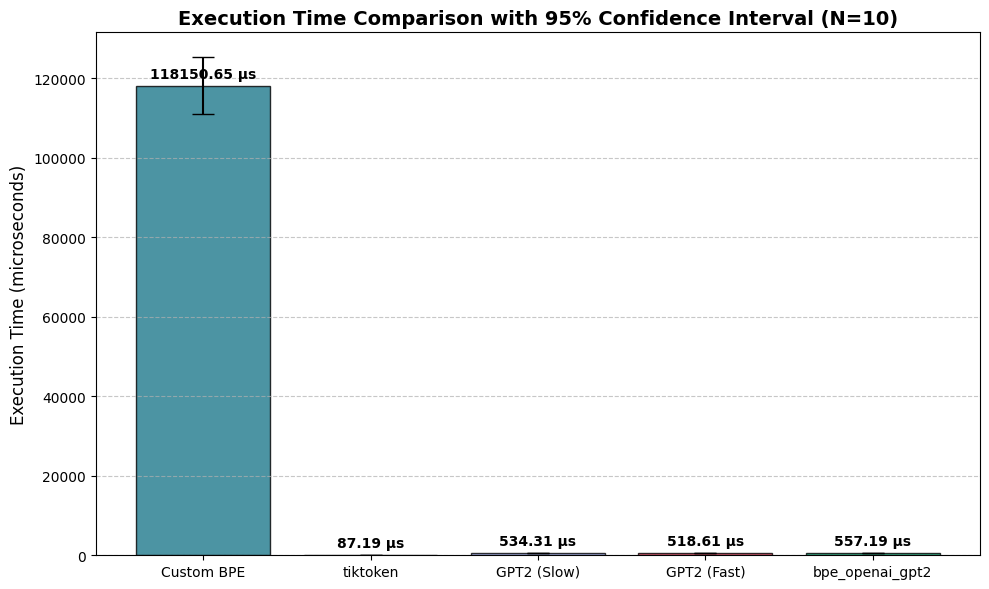

In [53]:

sample_text = test_corpus
N = 100

tokenizers = {
    "Custom BPE": lambda: encoder(apply_bpe(preprocess(sample_text), merges), char_to_id),
    "tiktoken": lambda: tokenizer_tiktoken.encode(sample_text),
    "GPT2 (Slow)": lambda: tokenizer_gpt2_slow(sample_text)['input_ids'],
    "GPT2 (Fast)": lambda: tokenizer_gpt2_fast(sample_text)['input_ids'],
    "bpe_openai_gpt2": lambda: tokenizer_gpt2.encode(sample_text)
}

results = {}

for name, tokenize_fn in tokenizers.items():
    times = []
    for _ in range(N):
        start_time = time.perf_counter()
        tokenize_fn()
        end_time = time.perf_counter()
        times.append((end_time - start_time) * 1e6) # Convert to microseconds

    times = np.array(times)
    mean = np.mean(times)
    std = np.std(times, ddof=1)
    # 95% Confidence Interval
    sem = std / np.sqrt(N)
    ci95 = sem * stats.t.ppf((1 + 0.95) / 2., N - 1)

    results[name] = {
        "mean": mean,
        "std": std,
        "ci95": ci95,
        "times": times
    }

# Print Summary
print(f"{'Tokenizer':<20} | {'Mean (µs)':<12} | {'Std Dev (µs)':<12} | {'95% CI (µs)':<12}")
print("-" * 65)
for name, stats_dict in results.items():
    print(f"{name:<20} | {stats_dict['mean']:<12.3f} | {stats_dict['std']:<12.3f} | {stats_dict['ci95']:<12.3f}")

# Plotting
names = list(results.keys())
means = [results[name]['mean'] for name in names]
errors = [results[name]['ci95'] for name in names]

plt.figure(figsize=(10, 6))
bars = plt.bar(names, means, yerr=errors, capsize=8, color=['#1F7A8C', '#5A6B7B', '#A5B4FC', '#F43F5E', '#10B981'], edgecolor='black', alpha=0.8)
plt.ylabel('Execution Time (microseconds)', fontsize=12)
plt.title('Execution Time Comparison with 95% Confidence Interval (N=10)', fontsize=14, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add values on top of the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + (max(means)*0.01), f"{yval:.2f} µs", ha='center', va='bottom', fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۶</b>
<br><br>

همانطور که مشاهده می‌شود خروجی توکنایزر ساخته شده در این تمرین با توکنایزهای دیگر متفاوت است. توکنایزرهای دیگر نشان می‌دهند که فشرده‌سازی بهتری می‌توانند انجام دهند چون تعداد توکن‌های کمتری نسبت به توکنایزر من تولید کردند.

همچنین سایز Vocab دیگر توکنایزرها به ۵۰ هزار می‌رسد در حالی که توکنایزر ما ۱۵۰۰ است.

در نمودار مقایسه‌ای همانطور که می‌بینیم سرعت دیگر توکنایزرها به شدت بهتر است. در این نمودار ۱۰۰ بار آزمایش تکرار شده است و با بازه اطمینان ۹۵٪ نتایج گزارش شده است.

توکنایزرهای آماده بسیار سریع‌تر عمل کردند چون پیاده‌سازی آن‌ها با زبان پایتون انجام نشده است مثلا با Rust یا C پیاده‌سازی شده‌اند. همچنین
استفاده از ساختمان‌داده‌های بهینه‌تر می‌تواند سربار اجرایی را در سورت کردن فراوانی ادغام‌ها کاهش دهد که در پیاده‌سازی ما این کار انجام نشده است. و استفاده از پردازش موازی می‌تواند 
سرعت را بالاتر ببرد در حالی که در این پیاده‌سازی به صورت موازی پردازش نمی‌شود.

</div>

<div dir="rtl" align="right">

## ۲. مدل‌سازی زبانی با N-gram

در این بخش، مدل‌های زبانی N-gram را پیاده‌سازی و ارزیابی می‌کنیم. هدف، درک trade-off بین مرتبه‌های مختلف N-gram و نقش حیاتی تکنیک‌های هموارسازی و backoff در مقابله با مشکل پراکندگی داده (data sparsity) است. ابتدا مدل‌های MLE با N=1 تا N=4 را می‌سازیم، سپس سه روش هموارسازی (Laplace، Linear Interpolation و Backoff) را پیاده‌سازی کرده و عملکرد آن‌ها را با معیار Perplexity روی داده‌ی test مقایسه می‌کنیم. در پایان، از بهترین مدل برای تولید متن استفاده خواهیم کرد.

</div>

<div dir="rtl" align="right">

### ۲.۱ بارگذاری و پیش‌پردازش دادگان (۱۰ نمره)

**صورت مسئله**

در این بخش از دادگان **Penn Treebank** برای آموزش مدل‌های زبانی N-gram استفاده می‌کنیم. این دادگان شامل سه بخش train، validation و test است. متن هر خط یک جمله است و باید پیش از آموزش، توکنایز شده و توکن‌های مرزی ابتدا و انتهای جمله به آن اضافه شوند. همچنین باید واژگان از داده‌ی train ساخته شود و کلمات خارج از واژگان با `<unk>` جایگزین شوند.

**آنچه باید انجام دهید**

- سه فایل `ptb.train.txt`، `ptb.valid.txt` و `ptb.test.txt` را بارگذاری کنید.
- هر جمله را توکنایز کرده و توکن‌های مرزی `<s>` و `</s>` را به ابتدا و انتهای آن اضافه کنید. (برای توکنایز کردن امکان استفاده از کتابخانه های آماده می باشد)
- واژگان را از داده‌ی train بسازید و در صورت نیاز از `<unk>` برای کلمات نادر استفاده کنید.
- تعداد جملات هر بخش و اندازه‌ی واژگان را گزارش دهید.
- توضیح دهید اگر توکن‌های `<s>` و `</s>` را اضافه نمی‌کردیم، محاسبه‌ی احتمال جمله چگونه تحت تأثیر قرار می‌گرفت.

</div>

In [54]:
# ==============================================================
# Part 2.1 — Loading and Preprocessing the Penn Treebank Dataset
# ==============================================================

# WRITE YOUR CODE HERE
# Load the dataset after logging in
# Download dataset
path = kagglehub.dataset_download("aliakay8/penn-treebank-dataset")

print("Dataset downloaded to:", path)

# List downloaded files
print(os.listdir(path))

Using Colab cache for faster access to the 'penn-treebank-dataset' dataset.
Dataset downloaded to: /kaggle/input/penn-treebank-dataset
['ptbdataset']


In [55]:

# Load train, validation, and test datasets
data_dir = os.path.join(path, "ptbdataset")

def load_text(filename):
    with open(os.path.join(data_dir, filename), "r", encoding="utf-8") as f:
        return f.read()

train_text = load_text("ptb.train.txt")
val_text   = load_text("ptb.valid.txt")
test_text  = load_text("ptb.test.txt")

# Check sizes
print("Train:", len(train_text), "characters")
print("Validation:", len(val_text), "characters")
print("Test:", len(test_text), "characters")

Train: 5101618 characters
Validation: 399782 characters
Test: 449945 characters


In [88]:
print('Number of sentences in train:', len(train_text.split('\n')))
print('Number of sentences in test:', len(test_text.split('\n')))
print('Number of sentences in validation:', len(val_text.split('\n')))

Number of sentences in train: 42069
Number of sentences in test: 3762
Number of sentences in validation: 3371


In [56]:
train_text[:300]

' aer banknote berlitz calloway centrust cluett fromstein gitano guterman hydro-quebec ipo kia memotec mlx nahb punts rake regatta rubens sim snack-food ssangyong swapo wachter \n pierre <unk> N years old will join the board as a nonexecutive director nov. N \n mr. <unk> is chairman of <unk> n.v. the d'

Remove `<unk>` from dataset

Now train a tokenizer

In [57]:
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.normalizers import NFD, Lowercase, Sequence, StripAccents
from tokenizers.pre_tokenizers import ByteLevel, Whitespace
from tokenizers.trainers import BpeTrainer
from tokenizers.processors import TemplateProcessing

In [58]:
tokenizer = Tokenizer(BPE(unk_token="<unk>"))

In [59]:
tokenizer.normalizer = Sequence([NFD(), Lowercase(), StripAccents()])
print(tokenizer.normalizer.normalize_str("Héllò hôw are ü?"))

hello how are u?


In [60]:
tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=False)
tokenizer.pre_tokenizer.pre_tokenize_str("Let's test my pre-tokenizer.")

[('Let', (0, 3)),
 ("'s", (3, 5)),
 ('Ġtest', (5, 10)),
 ('Ġmy', (10, 13)),
 ('Ġpre', (13, 17)),
 ('-', (17, 18)),
 ('tokenizer', (18, 27)),
 ('.', (27, 28))]

How unseen tokens will be look like...

In [61]:
trainer = BpeTrainer(vocab_size=10_000, special_tokens=["<unk>", "<s>", "</s>"])
# tokenizer.train_from_iterator(train_text.splitlines(), trainer=trainer)
tokenizer.train_from_iterator('Hello how are you', trainer=trainer)

In [62]:
encoding = tokenizer.encode("Let's test this tokenizer.")
print(encoding.tokens)

['l', 'e', '<unk>', '<unk>', '<unk>', 'Ġ', '<unk>', 'e', '<unk>', '<unk>', 'Ġ', '<unk>', 'h', '<unk>', '<unk>', 'Ġ', '<unk>', 'o', '<unk>', 'e', '<unk>', '<unk>', '<unk>', 'e', 'r', '<unk>']


Train again with read dataset

In [63]:
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.normalizers import NFD, Lowercase, Sequence, StripAccents
from tokenizers.pre_tokenizers import ByteLevel, Whitespace
from tokenizers.trainers import BpeTrainer
from tokenizers.processors import TemplateProcessing
from tokenizers.decoders import ByteLevel as ByteLevelDecoder


train_sentences = [
    " ".join(line.split())
    for line in train_text.splitlines()
    if line.strip()
]

tokenizer = Tokenizer(BPE(unk_token="<unk>"))
tokenizer.normalizer = Sequence([NFD(), Lowercase(), StripAccents()])
tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=False)
tokenizer.decoder = ByteLevelDecoder() # The decoder will convert Ġ back into actual spaces.
trainer = BpeTrainer(vocab_size=10_000, special_tokens=["<unk>", "<s>", "</s>"])
tokenizer.train_from_iterator(train_sentences, trainer=trainer)
encoding = tokenizer.encode("Let's test this tokenizer.")
print(encoding.tokens)

['let', "'", 's', 'Ġtest', 'Ġthis', 'Ġto', 'ken', 'izer', '.']


In [64]:
tokenizer

Tokenizer(version="1.0", truncation=None, padding=None, added_tokens=[{"id":0, "content":"<unk>", "single_word":False, "lstrip":False, "rstrip":False, "normalized":False, "special":True}, {"id":1, "content":"<s>", "single_word":False, "lstrip":False, "rstrip":False, "normalized":False, "special":True}, {"id":2, "content":"</s>", "single_word":False, "lstrip":False, "rstrip":False, "normalized":False, "special":True}], normalizer=Sequence(normalizers=[NFD(), Lowercase(), StripAccents()]), pre_tokenizer=ByteLevel(add_prefix_space=False, trim_offsets=True, use_regex=True), post_processor=None, decoder=ByteLevel(add_prefix_space=True, trim_offsets=True, use_regex=True), model=BPE(dropout=None, unk_token="<unk>", continuing_subword_prefix=None, end_of_word_suffix=None, fuse_unk=False, byte_fallback=False, ignore_merges=False, vocab={"<unk>":0, "<s>":1, "</s>":2, "#":3, "$":4, "&":5, "'":6, "*":7, "-":8, ".":9, "/":10, "0":11, "1":12, "2":13, "3":14, "4":15, "5":16, "6":17, "7":18, "8":19, "

Post processing

In [65]:

tokenizer.post_processor = TemplateProcessing(
    single="<s> $A </s>",
    special_tokens=[
        ("<s>", tokenizer.token_to_id("<s>")),
        ("</s>", tokenizer.token_to_id("</s>"))
    ]
)

In [66]:
encoding = tokenizer.encode("Let's test this tokenizer...", add_special_tokens=True)
print(encoding.tokens)
print(encoding.ids)

['<s>', 'let', "'", 's', 'Ġtest', 'Ġthis', 'Ġto', 'ken', 'izer', '.', '.', '.', '</s>']
[1, 3197, 6, 42, 1366, 292, 82, 5093, 8280, 9, 9, 9, 2]


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۱</b>
<br><br>

دیتاست لود شد و تعداد کاراکترها و تعداد جملات آن چاپ شد. مثلا برای دیتاست آموزش تعداد کاراکترها برابر 5101618  بود و تعداد جملات ۴۲۰۶۹ بود.

از کتابخانه tokenizers از huggingface استفاده شد.

ابتدا normalizer برای آن تنظیم شد تا ابتدا کاراکترهای unicdode اصلاح شوند و بعد lowercase شوند و بعد کاراکترهای خاص الفبای انگلیسی که مخصوص گویش‌های خاص است حذف شود.

در pre_tokenizer از ByteLevel استفاده شد. در اینجا باعث می‌شود قبل از این که الگوریتم BPE اجرا شود، کاراکترها بایت به بایت جدا شوند تا شبیه GPT باشد. حالت دیگری به اسم Whitespace هم وجود داشت
که بر اساس فاصله جدا می‌کرد.

برای آموزش توکنایزر دیتاست آموزش بر اساس \n به لیستی از جملات تبدیل شد. در ادامه هر جمله strip() شد تا کاراکتر اضافی نداشته باشد. چون حین آموزش مدل gram دیده می‌شد که پایان جملات با اسپیس تمام می‌شود در نتیجه مدل به جای ادامه دادن تولید یک توکن جدید با تولید توکن خاص </s> کار خود را تمام می‌کرد.

سپس با اضافه کردن post processing توکن‌های خاص `<s>` به ابتدا و آخر اضافه شدند.

برای آن که مشخص باشد مدل هنگام inference چه زمانی باید تولید توکن را پایان دهد حداقل باید یک توکن ویژه داشته باشیم. ولی برای شروع جمله‌ها نیاز به توکن ویژه نیست. ولی اگر مدل ما 
Unigram نباشد یعنی از context توکن‌های قبلی استفاده می‌کند، اینجا برای شروع جمله هم نیاز به توکن ویژه داریم تا در محاسبه احتمال دچار مشکل نشویم.

</div>

<div dir="rtl" align="right">

### ۲.۲ پیاده‌سازی مدل N-gram (۲۰ نمره)

**صورت مسئله**

مدل زبانی N-gram احتمال یک توکن را بر اساس N-1 توکن قبلی تخمین می‌زند. در روش Maximum Likelihood Estimation (MLE)، این احتمال از نسبت شمارش N-gram به شمارش کانتکست به‌دست می‌آید. برای ارزیابی مدل، از معیار **Perplexity** استفاده می‌کنیم که معکوس احتمال نرمال‌شده‌ی مجموعه‌ی test است.

**آنچه باید انجام دهید**

- یک مدل زبانی N-gram پیاده‌سازی کنید که از هر مقدار N پشتیبانی کند.
- احتمال هر N-gram را با روش MLE محاسبه کنید.
- تابع محاسبه‌ی log-probability یک جمله و perplexity روی یک مجموعه را پیاده کنید.
- در محاسبات، کلمات خارج از واژگان را با `<unk>` جایگزین کنید.
- توضیح دهید در MLE اگر یک n-gram در train دیده نشده باشد، perplexity کل مجموعه چه می‌شود و در کد شما این حالت چگونه مدیریت شده است

</div>

In [67]:

from collections import Counter, defaultdict
from tqdm.auto import tqdm
import math


class N_Gram:
    def __init__(self, n, tokenizer):
        if n < 1:
            raise ValueError("n must be >= 1")

        self.n = n
        self.tokenizer = tokenizer

        # Count complete n-grams, their contexts, and possible next tokens
        self.ngram_counts = Counter()
        self.context_counts = Counter()
        self.next_token_counts = defaultdict(Counter)

        # Get sentence boundary token IDs
        self.bos_id = tokenizer.token_to_id("<s>")
        self.eos_id = tokenizer.token_to_id("</s>")

        if self.bos_id is None or self.eos_id is None:
            raise ValueError("Tokenizer must contain <s> and </s>")

    def _get_ngrams(self, sentence, training=False):
        # Tokenize the sentence, including <s> and </s>
        ids = self.tokenizer.encode(sentence, add_special_tokens=True).ids

        # Map unseen tokens to <unk> only during evaluation
        if not training:
            unk_id = self.tokenizer.token_to_id("<unk>")

            ids = [
                token_id if token_id in self.observed_token_ids else unk_id
                for token_id in ids
            ]

        if self.n == 1:
            ids = ids[1:] # Exclude <s> from unigram predictions
        else:
            # Add extra <s> tokens for n > 2 to complete initial contexts
            ids = [self.bos_id] * (self.n - 2) + ids

        # Sliding window: extract all consecutive n-token sequences
        return [
            tuple(ids[i:i + self.n])
            for i in range(len(ids) - self.n + 1)
        ]

    def train(self, sentences):
        # Reset counts so repeated training doesn't accumulate old statistics
        self.ngram_counts.clear()
        self.context_counts.clear()
        self.next_token_counts.clear()

        for sentence in tqdm(sentences, desc=f"Training {self.n}-gram"):
            if not sentence.strip():
                continue  # Ignore empty sentences

            for gram in self._get_ngrams(sentence, True):
                context = gram[:-1]  # Previous n-1 tokens
                word = gram[-1]      # Token to predict

                self.ngram_counts[gram] += 1
                self.context_counts[context] += 1
                self.next_token_counts[context][word] += 1

        # Build vocabulary of tokens actually observed during training
        self.observed_token_ids = {
            token_id
            for gram in self.ngram_counts
            for token_id in gram
        }

        print("Training completed.")
        print(f"Unique {self.n}-grams: {len(self.ngram_counts)}")

    def prob(self, ngram):
        # MLE: P(word | context) = count(context, word) / count(context)
        ngram = tuple(ngram)
        context = ngram[:-1]

        denominator = self.context_counts[context]

        if denominator == 0:
            return 0.0  # Unseen context: no smoothing

        return self.ngram_counts[ngram] / denominator

    def log_prob(self, sentence):
        log_p = 0.0

        # Sentence log-probability is the sum of conditional log-probabilities
        for gram in self._get_ngrams(sentence):
            p = self.prob(gram)

            if p == 0:
                return -math.inf  # An unseen n-gram makes P(sentence) = 0

            log_p += math.log(p)

        return log_p

    def perplexity(self, sentence):
        grams = self._get_ngrams(sentence)
        log_p = self.log_prob(sentence)

        if log_p == -math.inf:
            return math.inf

        # Perplexity = exp(-average log-probability per predicted token)
        return math.exp(-log_p / len(grams))

    def corpus_perplexity(self, sentences):
        total_log_prob = 0.0
        total_tokens = 0

        for sentence in sentences:
            if not sentence.strip():
                continue

            log_p = self.log_prob(sentence)

            if log_p == -math.inf:
                return math.inf

            total_log_prob += log_p
            total_tokens += len(self._get_ngrams(sentence))

        return math.exp(-total_log_prob / total_tokens)

    def inference(self, sentence, max_new_tokens=30):
        # Encode the original prompt
        tokens = self.tokenizer.encode(
            sentence, add_special_tokens=False
        ).ids

        unk_id = self.tokenizer.token_to_id("<unk>")

        # Preserve original tokens for output
        generated = tokens.copy()

        # Replace unseen tokens only in the model's context
        context_tokens = [
            token_id if token_id in self.observed_token_ids else unk_id
            for token_id in tokens
        ]

        for _ in range(max_new_tokens):
            if self.n == 1:
                context = ()
            else:
                padded = [self.bos_id] * (self.n - 1) + context_tokens
                context = tuple(padded[-(self.n - 1):])

            candidates = self.next_token_counts.get(context)

            if not candidates:
                break

            # Exclude <unk> from generation
            valid_candidates = {
                token_id: count
                for token_id, count in candidates.items()
                if token_id != unk_id
            }

            if not valid_candidates:
                break

            next_token = max(valid_candidates, key=valid_candidates.get)

            if next_token == self.eos_id:
                break

            # Update both lists with the generated token
            generated.append(next_token)
            context_tokens.append(next_token)
        else:
            print("Warning: max_new_tokens exceeded")

        return self.tokenizer.decode(
            generated, skip_special_tokens=True
        )


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۲</b>
<br><br>

در اینجا کلاس مدل N-gram پیاده‌سازی شده است. این کلاس می‌تواند برای هر N استفاده شود.
شامل توابع train و inference است. برای inference به صورت greedy بهترین احتمال و بالاترین توکن انتخاب می‌شود ولی توکن‌های خاصی مثل <unk> صرف نظر می‌شوند و بهترین توکن بعدی انتخاب می‌شود.

در تابع get_ngram توکن‌های context برای محاسبه احتمال استخراج می‌شود تا برای فرآیند آموزش یا محاسبه احتمال لگاریتمی یا پرپلکسیتی استفاده شود. چون ممکن است مدل برخی از توکن‌ها
را ندیده باشد، اگر مدل در فرآیند آموزش نباشد یعنی مثلا در حال محاسبه پرپلکسیتی یک جمله است، با مشکل مواجه می‌شود و پرپلکسیتی بی‌نهایت می‌شود. به همین خاطر در چنین موردی توکن‌های
دیده نشده با توکن خاص <unk> جایگزین می‌شود تا فرآیند محاسبه احتمال دچار مشکل نشود.

حل این مشکل فقط برای مدل‌های Unigram ممکن است که احتمال تک توکن را محاسبه می‌کنند. برای مدل‌های بالاتر جایگزین کردن توکن‌های دیده نشده با <unk> ممکن است کافی نباشد و همچنان پرپلکسیتی
را بی‌نهایت کند. برای حل این مشکل باید از smoothing استفاده کنیم که فعلا در اینجا پیاده‌سازی نشده است.

</div>

<div dir="rtl" align="right">

### ۲.۳ آموزش و ارزیابی مدل‌های MLE (۱۵ نمره)

**صورت مسئله**

مدل‌های MLE را با N=1 تا N=4 روی داده‌ی train آموزش دهید و perplexity هر کدام را روی داده‌ی test محاسبه کنید.

**آنچه باید انجام دهید**

- چهار مدل MLE با N=1، ۲، ۳ و ۴ روی داده‌ی train آموزش دهید.
- perplexity هر مدل را روی داده‌ی test محاسبه و گزارش کنید.
- روند perplexity از N=1 تا N=4 را تحلیل کنید؛ اگر برای N=4 افزایش یا کاهش دیدید آن را تحلیل و عوامل آن را بیان کنید.
- تعداد n-gramهای یکتا در train برای هر N را گزارش کنید و آن را نسبت به کل n-gramهای ممکن بسنجید.

</div>

#### 1-Gram model

In [68]:
model1 = N_Gram(1, tokenizer)
model1.train(train_sentences)

# Generate text
print(model1.inference("the company"))

# Calculate log-probability
print(model1.log_prob("the company said"))

# Calculate perplexity
print(model1.perplexity("the company said"))

print(model1.inference("N years old will"))
print(model1.perplexity("N years old"))

# Inspect counts
for ngram, count in model1.ngram_counts.most_common(10):
    tokens = [tokenizer.id_to_token(i) for i in ngram]
    print(tokens, ":", count)


Training 1-gram:   0%|          | 0/42068 [00:00<?, ?it/s]

Training completed.
Unique 1-grams: 8978
the company the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the
-19.396312312016136
127.62267744002204
n years old will the the the the the the the the the the the the the the the the the the the the the the the the the the the the the the
710.4890583298866
['<unk>'] : 45020
['Ġthe'] : 43728
['Ġ'] : 43399
['</s>'] : 42068
['Ġn'] : 36170
['Ġof'] : 24339
['Ġto'] : 23572
['Ġa'] : 20655
['Ġand'] : 16947
['.'] : 16709


#### 2-Gram model

In [69]:
# ==============================================================
# Part 2.3 — Training and Evaluating MLE Models (N=1..4)
# ==============================================================

# Initialize and train
model2 = N_Gram(2, tokenizer)
model2.train(train_sentences)

Training 2-gram:   0%|          | 0/42068 [00:00<?, ?it/s]

Training completed.
Unique 2-grams: 267080


In [70]:
model2._get_ngrams("Hello how are you")

[(1, 3076), (3076, 461), (461, 685), (685, 186), (186, 683), (683, 2)]

In [71]:
model2.ngram_counts

Counter({(1, 24): 878,
         (24, 61): 3,
         (61, 341): 1,
         (341, 3051): 1,
         (3051, 28): 7,
         (28, 3703): 1,
         (3703, 3374): 1,
         (3374, 49): 1,
         (49, 729): 1,
         (729, 137): 1,
         (137, 111): 1,
         (111, 914): 1,
         (914, 41): 1,
         (41, 209): 1,
         (209, 293): 1,
         (293, 44): 1,
         (44, 625): 1,
         (625, 172): 1,
         (172, 5533): 1,
         (5533, 106): 1,
         (106, 71): 1,
         (71, 67): 1,
         (67, 38): 1,
         (38, 9208): 1,
         (9208, 61): 1,
         (61, 316): 1,
         (316, 5748): 1,
         (5748, 27): 1,
         (27, 87): 7,
         (87, 8): 1,
         (8, 8227): 1,
         (8227, 2313): 6,
         (2313, 50): 1,
         (50, 300): 1,
         (300, 38): 1,
         (38, 272): 1,
         (272, 373): 1,
         (373, 1064): 1,
         (1064, 170): 1,
         (170, 105): 1,
         (105, 68): 1,
         (68, 35): 1,
         

In [72]:

# Generate text
print(model2.inference("the company", max_new_tokens=20))

# Calculate log-probability
print(model2.log_prob("the company said"))

# Calculate perplexity
print(model2.perplexity("the company said"))

# Inspect counts
for ngram, count in model2.ngram_counts.most_common(10):
    tokens = [tokenizer.id_to_token(i) for i in ngram]
    print(tokens, ":", count)

the company 's. ireland valley national over the ireland valley national over the ireland
-8.643146716969959
8.677961746300332
['Ġ', '<unk>'] : 43343
["Ġ'", 's'] : 9784
['Ġ$', 'Ġn'] : 7440
['Ġn', 'Ġn'] : 7172
['<s>', 'the'] : 7057
['Ġof', 'Ġthe'] : 5271
['Ġn', 'Ġmillion'] : 4485
['Ġin', 'Ġthe'] : 4166
['<unk>', 'Ġ'] : 4012
['Ġthe', 'Ġ'] : 3421


In [73]:
# Generate text
print(model2.inference("years old will join"))
print(model2.log_prob("N years old will join"))

years old will join the ireland valley national over the ireland valley national over the ireland valley national over the ireland valley national over the 
-inf


In [74]:
%pip install -q pympler

In [75]:
from pympler import asizeof

# Size of learned n-gram statistics (excluding tokenizer)
size = asizeof.asizeof(
    model2.ngram_counts,
    model2.context_counts,
    model2.next_token_counts
)

print(f"Model size: {size / 1024**2:.2f} MB")

Model size: 45.21 MB


#### 3-Gram model

In [76]:
model3 = N_Gram(3, tokenizer)
model3.train(train_sentences)

Training 3-gram:   0%|          | 0/42068 [00:00<?, ?it/s]

Training completed.
Unique 3-grams: 590403


In [77]:
# Generate text
print(model3.inference("the company"))

# Calculate log-probability
print(model3.log_prob("the company said"))

# Calculate perplexity
print(model3.perplexity("the company said"))

# Inspect counts
for ngram, count in model3.ngram_counts.most_common(10):
    tokens = [tokenizer.id_to_token(i) for i in ngram]
    print(tokens, ":", count)

the company said
-7.282643098198293
6.17593800455532
['<s>', '<s>', 'the'] : 7057
['<unk>', 'Ġ', '<unk>'] : 4010
['Ġ', '<unk>', 'Ġ'] : 3760
['Ġ$', 'Ġn', 'Ġmillion'] : 3581
['Ġthe', 'Ġ', '<unk>'] : 3411
['Ġ', '<unk>', '</s>'] : 3287
['Ġa', 'Ġ', '<unk>'] : 2375
['.', 'Ġ', '<unk>'] : 2110
['Ġ', '<unk>', 'Ġand'] : 1944
['<s>', '<s>', 'in'] : 1891


In [78]:
print(model3.inference("N years old"))
print(model3.perplexity("N years old"))

n years old was named president and chief executive officer of this year
inf


In [79]:
# Size of learned n-gram statistics (excluding tokenizer)
size = asizeof.asizeof(
    model3.ngram_counts,
    model3.context_counts,
    model3.next_token_counts
)

print(f"Model size: {size / 1024**2:.2f} MB")

Model size: 170.86 MB


#### 4-Gram

In [80]:
model4 = N_Gram(4, tokenizer)
model4.train(train_sentences)

Training 4-gram:   0%|          | 0/42068 [00:00<?, ?it/s]

Training completed.
Unique 4-grams: 776226


In [81]:
# Generate text
print(model4.inference("the company"))

# Calculate log-probability
print(model4.log_prob("the company said"))

# Calculate perplexity
print(model4.perplexity("the company said"))

print(model4.inference("N years old will"))
print(model4.perplexity("N years old"))

# Inspect counts
for ngram, count in model4.ngram_counts.most_common(10):
    tokens = [tokenizer.id_to_token(i) for i in ngram]
    print(tokens, ":", count)


the company said it expects to report a profit of $ n million or n cents a share
-inf
inf
n years old will be responsible for more than n n of the company 's 
inf
['<s>', '<s>', '<s>', 'the'] : 7057
['Ġ', '<unk>', 'Ġ', '<unk>'] : 3758
['<s>', '<s>', '<s>', 'in'] : 1891
['<s>', '<s>', '<s>', 'but'] : 1808
['Ġu', '.', 's', '.'] : 1744
['<s>', '<s>', '<s>', '<unk>'] : 1677
['<s>', '<s>', '<s>', 'mr'] : 1348
['<s>', '<s>', 'mr', '.'] : 1348
['<s>', '<s>', '<s>', 'it'] : 1128
['<s>', '<s>', '<s>', 'he'] : 898


#### Perplexity on test data

$$
\boxed{
\mathrm{PPL} = \exp\left(
-\frac{\sum_{i=1}^{S}\log P(s_i)}
{\sum_{i=1}^{S}N_i}
\right)
}
$$

1-gram: 652.82
2-gram: inf
3-gram: inf
4-gram: inf


/usr/local/lib/python3.13/dist-packages/matplotlib/transforms.py:2436: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


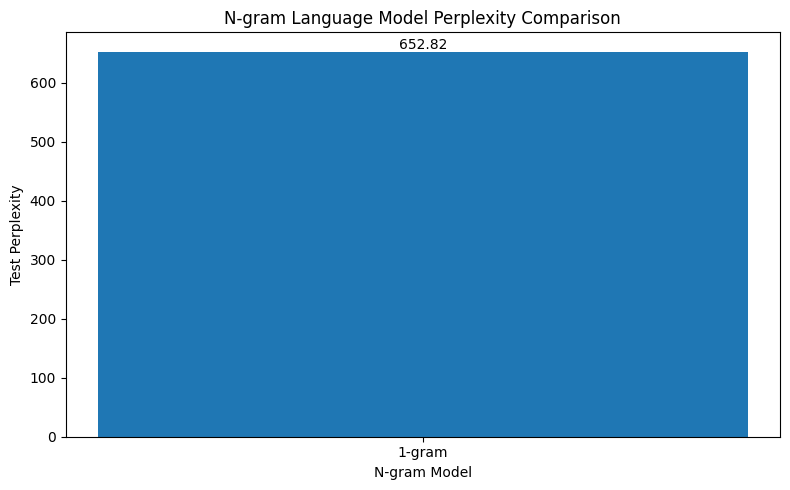

In [82]:
import matplotlib.pyplot as plt
import math

test_sentences = [
    " ".join(line.split())
    for line in test_text.splitlines()
    if line.strip()
]

models = [model1, model2, model3, model4]

n_values = []
perplexities = []

for model in models:
    ppl = model.corpus_perplexity(test_sentences)
    print(f"{model.n}-gram: {ppl:.2f}")

    n_values.append(f"{model.n}-gram")
    perplexities.append(ppl)

# Plot perplexity comparison
plt.figure(figsize=(8, 5))
bars = plt.bar(n_values, perplexities)

plt.xlabel("N-gram Model")
plt.ylabel("Test Perplexity")
plt.title("N-gram Language Model Perplexity Comparison")

for bar, ppl in zip(bars, perplexities):
    if math.isfinite(ppl):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{ppl:.2f}",
            ha="center",
            va="bottom"
        )

plt.tight_layout()
plt.show()

1-gram model size: 1.28 MB
2-gram model size: 45.21 MB
3-gram model size: 170.86 MB
4-gram model size: 317.07 MB


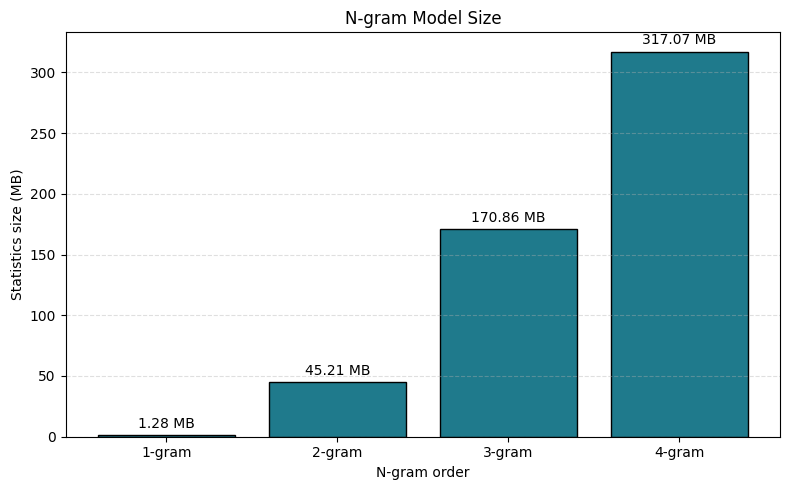

In [89]:
from pympler import asizeof
import matplotlib.pyplot as plt

models = [model1, model2, model3, model4]
model_sizes_mb = []

for model in models:
    size_bytes = asizeof.asizeof(
        model.ngram_counts,
        model.context_counts,
        model.next_token_counts,
    )
    model_sizes_mb.append(size_bytes / 1024**2)

for model, size_mb in zip(models, model_sizes_mb):
    print(f"{model.n}-gram model size: {size_mb:.2f} MB")

plt.figure(figsize=(8, 5))
bars = plt.bar(
    [f"{model.n}-gram" for model in models],
    model_sizes_mb,
    color="#1F7A8C",
    edgecolor="black",
)

plt.xlabel("N-gram order")
plt.ylabel("Statistics size (MB)")
plt.title("N-gram Model Size")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.bar_label(bars, fmt="%.2f MB", padding=3)
plt.tight_layout()
plt.show()

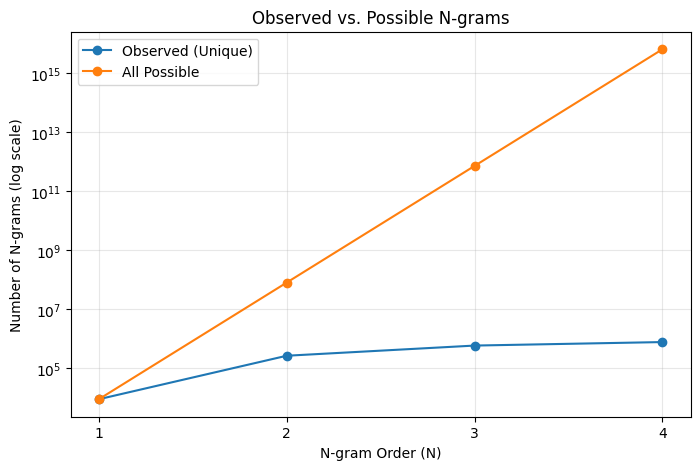

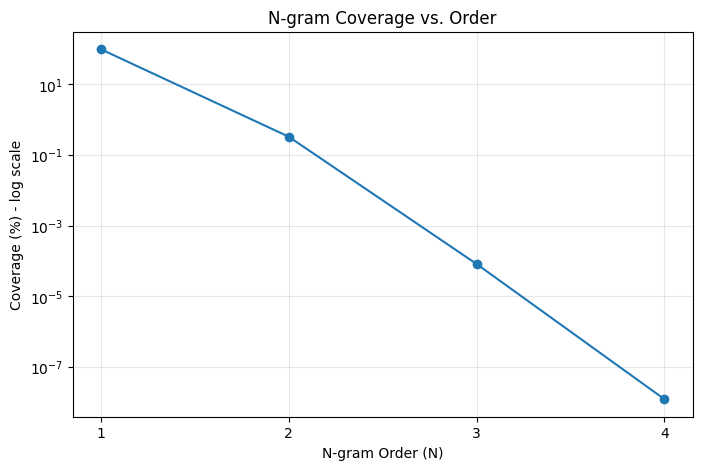

In [95]:
models = [model1, model2, model3, model4]

V = len(model1.observed_token_ids - {model1.bos_id})

n_values = [model.n for model in models]
unique_counts = [len(model.ngram_counts) for model in models]
possible_counts = [V ** n for n in n_values]
coverage = [
    unique / possible * 100
    for unique, possible in zip(unique_counts, possible_counts)
]

# Plot 1: Observed vs. possible N-grams
plt.figure(figsize=(8, 5))
plt.plot(n_values, unique_counts, marker="o", label="Observed (Unique)")
plt.plot(n_values, possible_counts, marker="o", label="All Possible")

plt.yscale("log")
plt.xticks(n_values)
plt.xlabel("N-gram Order (N)")
plt.ylabel("Number of N-grams (log scale)")
plt.title("Observed vs. Possible N-grams")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Plot 2: Vocabulary coverage
plt.figure(figsize=(8, 5))
plt.plot(n_values, coverage, marker="o")

plt.yscale("log")
plt.xticks(n_values)
plt.xlabel("N-gram Order (N)")
plt.ylabel("Coverage (%) - log scale")
plt.title("N-gram Coverage vs. Order")
plt.grid(True, alpha=0.3)
plt.show()

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۳</b>
<br><br>

یکی از مشکلات این بود که توکن خاص <unk> بسیار پرتکرار بود به طوری که مدل همیشه این توکن را به صورت متوالی با یک اسپیس تولید می‌کرد. برای حل این مشکل در متد inference این توکن exclude شد تا دیگر تولید نشود.

`['Ġ', '<unk>'] : 43343`

در مدل‌های ۱ و ۲ و ۳ می‌بینیم که توکن‌های بعدی تولید شده خیلی نامرتبط و حتی در مدل 1-gram میبینیم که یک توکن ثابت `the` در حال تولید شدن است چون مدل به صورت greedy بالاترین توکن با احتمال بالا را انتخاب می‌کند و در نهایت به ارور max limit token می‌رسد چون هیچ وقت توکن پایانی `</s>` را تولید نمی‌کند.

ولی در مدل 4-gram می‌بینیم که جملات به شکل درست با تولید توکن خاص پایان یافتند و ساختار آن‌ها بسیار بهتر است.

یکی از اشکالات پرتکرار این است که پرپلکسیتی جملات در مثال‌های بالا بی‌نهایت می‌شود. این به این خاطر است که در پیاده‌سازی این قسمت از مدل، از smoothing استفاده نشده است و مدل با دیدن یک توکن جدید احتمال صفر اختصاص می‌دهد.

همچنین در نمودار نهایی رسم شده برای مقایسه پرپلکسیتی دیده می‌شود که تمام مدل‌ها پرپلکسیتی بی‌نهایت دارند که این مشکل باید با پیاده‌سازی smoothing رفع شود.

پرپلکسیتی تمام مدل‌ها حتی 1-gram هم دیده شد که بی‌نهایت می‌شود. در نتیجه کد مدل تغییر داده شد تا مدل در مواجهه با توکن‌های جدید آن‌ها را به توکن `<unk>` تغییر دهد.

سایز مدل‌های آموزش دیده شده از ۱ تا ۴ در سلول‌های بالا نمایش داده شده است مثلا مدل 4-gram برابر ۳۱۷ مگابایت است.

زمانی که N زیاد می شود، ترکیب‌های ممکن واژه‌ها هم به صورت نمایی زیاد می‌شود. ولی مدل ما نمی‌تواند تمام این ترکیب‌ها را حداقل در دیتاست
آموزش ببیند یا به خاطر محدودیت حجم آن‌ها را ذخیره کند. پس فقط بخش کوچکی از تمام ترکیب‌های ممکن را می‌تواند ببیند. در سلول‌های بالاتر یک نمودار مقایسه‌ای از تعداد ترکیب‌های ممکن و تعداد ترکیب‌های دیده شده توسط مدل آورده شده است. همچنین میزان coverage هم گزارش شده است که نشان می‌دهد پوشش مدل روی ترکیب‌ها بسیار پایین است. مدل 1-gram توانسته پوشش ۱۰۰ درصدی داشته باشد ولی برای مدل‌های بالاتر این درصد پوشش به صورت نمایی کاهش یافته است.

</div>

<div dir="rtl" align="right">

### ۲.۴ هموارسازی و Backoff (۱۵ نمره)

**صورت مسئله**

برای مقابله با مشکل N-gram های دیده‌نشده، از تکنیک‌های هموارسازی و backoff استفاده می‌کنیم. در این زیربخش سه روش رایج را روی مدل trigram پیاده‌سازی و مقایسه می‌کنیم:

- **Add-1 (Laplace):** افزودن یک واحد به تمام شمارش‌ها
- **Linear Interpolation:** ترکیب خطی احتمال‌های unigram، bigram و trigram با وزن‌های λ
- **Backoff:** در صورت نبود trigram، به bigram و سپس unigram با ضریب α برمی‌گردیم

وزن‌های λ و ضریب α باید روی داده‌ی validation تنظیم شده و بهترین مقدار روی test ارزیابی شود.


**آنچه باید انجام دهید**

- هر سه روش هموارسازی/backoff را پیاده‌سازی کنید.
- برای Linear Interpolation، حداقل ۵ ترکیب مختلف λ را روی validation تست کنید و بهترین را انتخاب کنید؛ جدول perplexity-validation را گزارش کنید.
- برای Backoff، چند مقدار مختلف α را روی validation تست کنید و منحنی perplexity-α را رسم کنید.
- perplexity بهترین مدل هر روش را روی test گزارش دهید.
- تحلیل کنید چرا α خیلی کوچک یا خیلی بزرگ بدتر عمل می‌کند، و کدام روش برای کدام N بهتر است.
- توضیح دهید چرا Laplace در واژگان بزرگ‌تر ضعیف‌تر عمل می‌کند.

</div>

In [83]:

import math


class SmoothedNGramBase(N_Gram):
    """Reuse an already-trained N_Gram without modifying it."""

    def __init__(self, model, unigram_model):
        super().__init__(model.n, model.tokenizer)

        # Share trained counts; no retraining required.
        self.ngram_counts = model.ngram_counts
        self.context_counts = model.context_counts
        self.next_token_counts = model.next_token_counts

        # Common vocabulary across all N-gram orders.
        self.vocab_ids = (
            set(unigram_model.observed_token_ids)
            - {self.bos_id}
        )

        self.unk_id = self.tokenizer.token_to_id("<unk>")
        if self.unk_id is None:
            raise ValueError("Tokenizer must contain <unk>")

        self.vocab_ids.add(self.unk_id)
        self.observed_token_ids = self.vocab_ids | {self.bos_id}
        self.V = len(self.vocab_ids)


class LaplaceNGram(SmoothedNGramBase):
    """Add-one (Laplace) smoothing for any N."""

    def prob(self, ngram):
        ngram = tuple(ngram)
        context = ngram[:-1]
        word = ngram[-1]

        if word not in self.vocab_ids:
            return 0.0

        count = self.ngram_counts[ngram]
        context_count = self.context_counts[context]

        return (count + 1) / (context_count + self.V)


class InterpolationNGram(SmoothedNGramBase):
    """Linear interpolation of unigram, bigram, trigram."""

    def __init__(
        self, unigram, bigram, trigram,
        lambdas=(0.2, 0.3, 0.5)
    ):
        super().__init__(trigram, unigram)

        self.unigram = unigram
        self.bigram = bigram
        self.trigram = trigram
        self.set_lambdas(lambdas)

    def set_lambdas(self, lambdas):
        if len(lambdas) != 3:
            raise ValueError("Provide three lambda weights")

        if any(x < 0 for x in lambdas):
            raise ValueError("Lambdas must be nonnegative")

        if not math.isclose(sum(lambdas), 1.0, abs_tol=1e-9):
            raise ValueError("Lambdas must sum to 1")

        self.lambdas = tuple(lambdas)

    def prob(self, ngram):
        w1, w2, w3 = ngram
        l1, l2, l3 = self.lambdas

        if w3 not in self.vocab_ids:
            return 0.0

        p1 = self.unigram.prob((w3,))
        p2 = self.bigram.prob((w2, w3))
        p3 = self.trigram.prob((w1, w2, w3))

        return l1 * p1 + l2 * p2 + l3 * p3


class BackoffNGram(SmoothedNGramBase):
    """
    Normalized backoff for trigram language modeling.

    alpha is the probability mass reserved for unseen
    continuations when a context has been observed.

    Unseen contexts back off completely.
    The unigram base uses Laplace smoothing.
    """

    def __init__(
        self, unigram, bigram, trigram, alpha=0.2
    ):
        super().__init__(trigram, unigram)

        self.unigram = unigram
        self.bigram = bigram
        self.trigram = trigram

        self.unigram_laplace = LaplaceNGram(
            unigram, unigram
        )

        self._cache = {}
        self.set_alpha(alpha)

    def set_alpha(self, alpha):
        if not 0 < alpha < 1:
            raise ValueError("alpha must be between 0 and 1")

        self.alpha = alpha
        self._cache.clear()

    def _lower_prob(self, order, gram):
        """Return probability from the next lower order."""
        if order == 3:
            return self._backoff(2, gram[1:])

        return self.unigram_laplace.prob(gram[1:])

    def _backoff(self, order, gram):
        gram = tuple(gram)

        if order == 1:
            return self.unigram_laplace.prob(gram)

        model = self.trigram if order == 3 else self.bigram
        context = gram[:-1]
        count = model.ngram_counts[gram]
        context_count = model.context_counts[context]

        # Completely unseen context: use lower-order model.
        if context_count == 0:
            return self._lower_prob(order, gram)

        # Find the lower-order probability mass assigned
        # to words already seen in this context.
        cache_key = (order, context)

        if cache_key not in self._cache:
            seen_words = model.next_token_counts[context]

            seen_mass = sum(
                self._lower_prob(order, context + (word,))
                for word in seen_words
            )

            self._cache[cache_key] = max(
                0.0, 1.0 - seen_mass
            )

        unseen_mass = self._cache[cache_key]

        # No unseen continuations with positive lower-order
        # mass: use the ordinary MLE distribution.
        if unseen_mass <= 1e-12:
            return count / context_count

        if count > 0:
            # Observed continuation.
            return (1 - self.alpha) * (
                count / context_count
            )

        # Unseen continuation: redistribute reserved mass
        # according to lower-order probabilities.
        lower_p = self._lower_prob(order, gram)

        return self.alpha * lower_p / unseen_mass

    def prob(self, ngram):
        ngram = tuple(ngram)

        if ngram[-1] not in self.vocab_ids:
            return 0.0

        return self._backoff(3, ngram)


#### Laplace

In [84]:
import builtins
sum = builtins.sum

laplace_models = [
    LaplaceNGram(model, model1)
    for model in [model1, model2, model3, model4]
]

In [85]:
laplace_perplexities = {}

for model in laplace_models:
    ppl = model.corpus_perplexity(test_sentences)
    laplace_perplexities[model.n] = ppl
    print(f"Laplace {model.n}-gram: {laplace_perplexities[model.n]:.2f}")

Laplace 1-gram: 653.30
Laplace 2-gram: 482.82
Laplace 3-gram: 1944.50
Laplace 4-gram: 3835.08


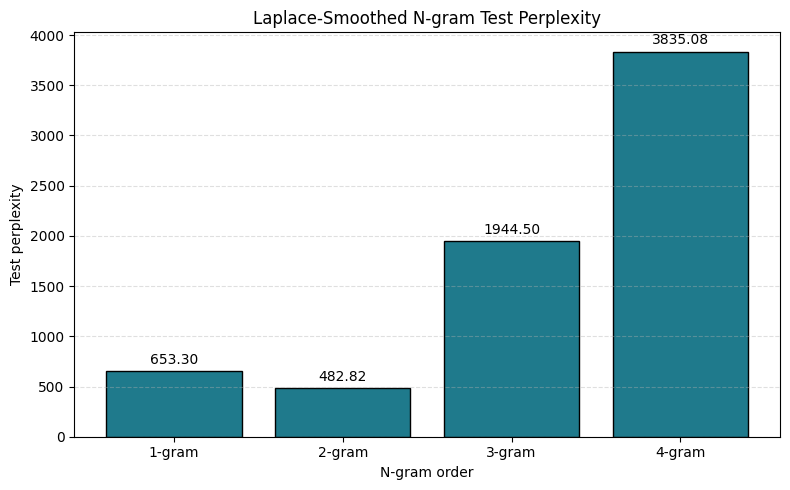

In [86]:
n_values = sorted(laplace_perplexities)
labels = [f"{n}-gram" for n in n_values]
ppl_values = [laplace_perplexities[n] for n in n_values]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, ppl_values, color="#1F7A8C", edgecolor="black")

ax.set_xlabel("N-gram order")
ax.set_ylabel("Test perplexity")
ax.set_title("Laplace-Smoothed N-gram Test Perplexity")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.bar_label(bars, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

#### Interpolation

In [96]:
# Lambda order: (unigram, bigram, trigram)
lambda_options = [
    (0.1, 0.1, 0.8),
    (0.1, 0.3, 0.6),
    (0.2, 0.3, 0.5),
    (0.3, 0.3, 0.4),
    (0.3, 0.35, 0.35), # Best so far :)))
    (0.4, 0.3, 0.3),
    (0.5, 0.3, 0.2),
    (0.5, 0.4, 0.1),
]


val_sentences = [
    " ".join(line.split())
    for line in val_text.splitlines()
    if line.strip()
]

interpolation_perplexities = {}
interpolation = InterpolationNGram(
    unigram=model1,
    bigram=model2,
    trigram=model3,
    lambdas=(0.2, 0.3, 0.5),
)

for weights in lambda_options:
    interpolation.set_lambdas(weights)
    ppl = interpolation.corpus_perplexity(val_sentences)
    interpolation_perplexities[weights] = ppl
    print(
        f"lambda={weights}, "
        f"PPL={interpolation_perplexities[weights]:.2f}"
    )

lambda=(0.1, 0.1, 0.8), PPL=170.07
lambda=(0.1, 0.3, 0.6), PPL=133.58
lambda=(0.2, 0.3, 0.5), PPL=122.77
lambda=(0.3, 0.3, 0.4), PPL=120.14
lambda=(0.3, 0.35, 0.35), PPL=118.04
lambda=(0.4, 0.3, 0.3), PPL=121.97
lambda=(0.5, 0.3, 0.2), PPL=128.19
lambda=(0.5, 0.4, 0.1), PPL=130.67


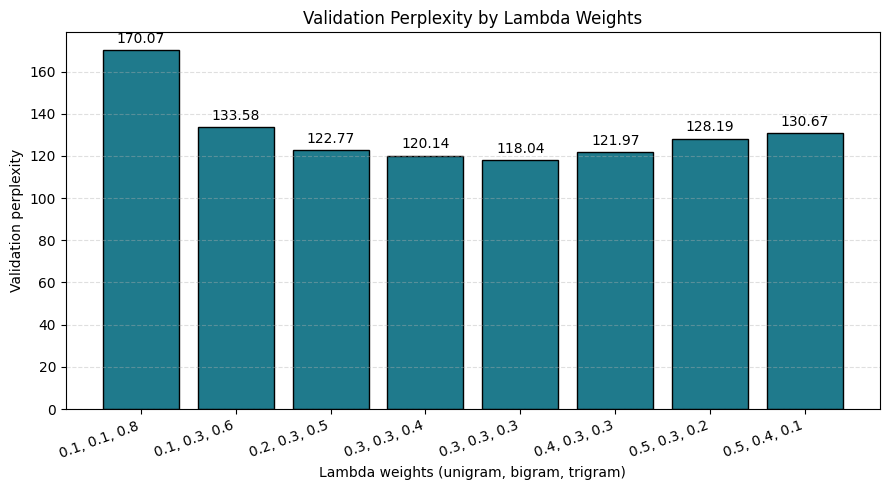

In [97]:
lambda_labels = [
    ", ".join(f"{weight:.1f}" for weight in weights)
    for weights in interpolation_perplexities
]
ppl_values = list(interpolation_perplexities.values())

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(lambda_labels, ppl_values, color="#1F7A8C", edgecolor="black")

ax.set_xlabel("Lambda weights (unigram, bigram, trigram)")
ax.set_ylabel("Validation perplexity")
ax.set_title("Validation Perplexity by Lambda Weights")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.bar_label(bars, fmt="%.2f", padding=3)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Best lambda values (unigram, bigram, trigram): (0.3, 0.35, 0.35)
Validation perplexity: 118.04
Test perplexity: 111.19


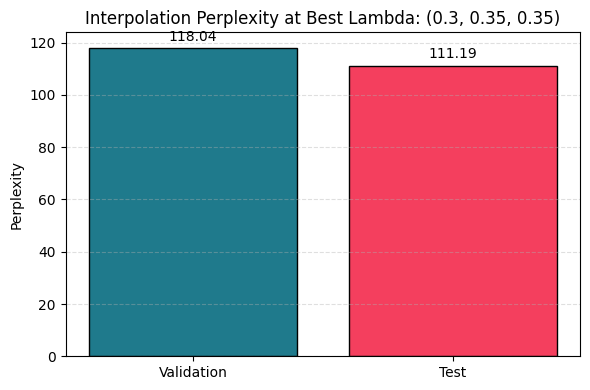

In [98]:
best_lambdas = min(
    interpolation_perplexities,
    key=interpolation_perplexities.get
)
best_validation_ppl = interpolation_perplexities[best_lambdas]

interpolation.set_lambdas(best_lambdas)
best_test_ppl = interpolation.corpus_perplexity(test_sentences)

print(f"Best lambda values (unigram, bigram, trigram): {best_lambdas}")
print(f"Validation perplexity: {best_validation_ppl:.2f}")
print(f"Test perplexity: {best_test_ppl:.2f}")

labels = ["Validation", "Test"]
values = [best_validation_ppl, best_test_ppl]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, values, color=["#1F7A8C", "#F43F5E"], edgecolor="black")

ax.set_ylabel("Perplexity")
ax.set_title(f"Interpolation Perplexity at Best Lambda: {best_lambdas}")
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

#### Backoff

In [100]:
alpha_options = [0.01, 0.05, 0.1, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6, 0.8]
alpha_results = {}

backoff = BackoffNGram(
    unigram=model1,
    bigram=model2,
    trigram=model3,
    alpha=0.2,
)

for alpha in alpha_options:
    backoff.set_alpha(alpha)
    ppl = backoff.corpus_perplexity(val_sentences)
    alpha_results[alpha] = ppl
    print(f"alpha={alpha}, PPL={ppl:.2f}")

alpha=0.01, PPL=437.08
alpha=0.05, PPL=213.66
alpha=0.1, PPL=162.66
alpha=0.2, PPL=131.40
alpha=0.25, PPL=125.66
alpha=0.3, PPL=122.91
alpha=0.35, PPL=122.31
alpha=0.4, PPL=123.48
alpha=0.5, PPL=130.79
alpha=0.6, PPL=146.01
alpha=0.8, PPL=231.40


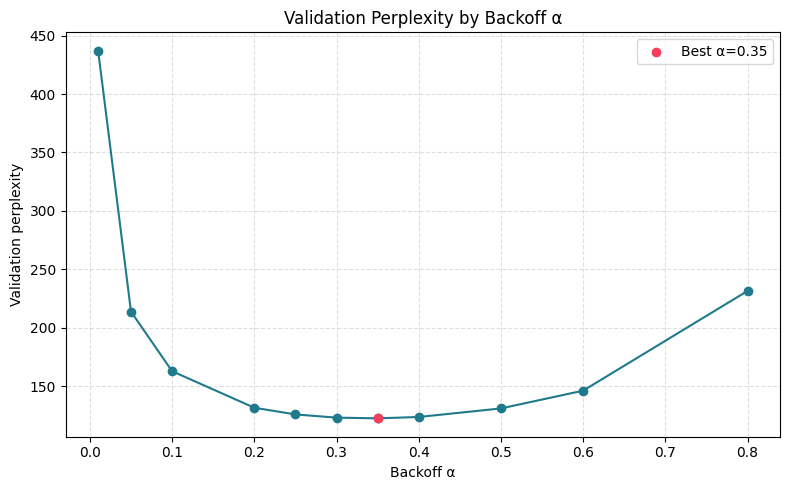

In [101]:
alpha_values = sorted(alpha_results)
ppl_values = [alpha_results[alpha] for alpha in alpha_values]

plt.figure(figsize=(8, 5))
plt.plot(alpha_values, ppl_values, marker="o", color="#1F7A8C")

best_index = min(range(len(ppl_values)), key=ppl_values.__getitem__)
plt.scatter(alpha_values[best_index], ppl_values[best_index], color="#F43F5E", zorder=3,
            label=f"Best α={alpha_values[best_index]:.2f}")

plt.xlabel("Backoff α")
plt.ylabel("Validation perplexity")
plt.title("Validation Perplexity by Backoff α")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

Best backoff alpha: 0.35
Validation perplexity: 122.31
Test perplexity: 115.94


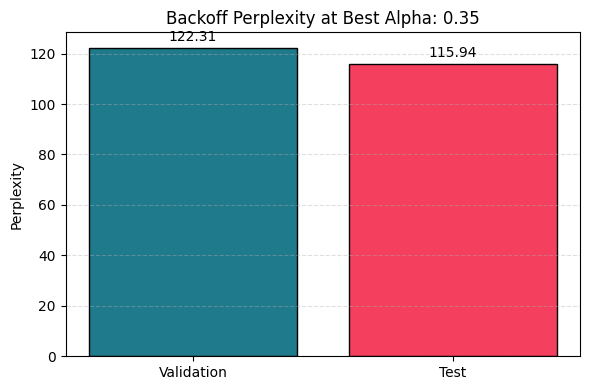

In [102]:
best_alpha = min(alpha_results, key=alpha_results.get)
best_validation_ppl = alpha_results[best_alpha]

backoff.set_alpha(best_alpha)
best_test_ppl = backoff.corpus_perplexity(test_sentences)

print(f"Best backoff alpha: {best_alpha}")
print(f"Validation perplexity: {best_validation_ppl:.2f}")
print(f"Test perplexity: {best_test_ppl:.2f}")

labels = ["Validation", "Test"]
values = [best_validation_ppl, best_test_ppl]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, values, color=["#1F7A8C", "#F43F5E"], edgecolor="black")

ax.set_ylabel("Perplexity")
ax.set_title(f"Backoff Perplexity at Best Alpha: {best_alpha}")
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۴</b>
<br><br>

یکی از موارد عجیبی که دیده شد این بود که مدل‌های با N-gram بالا پرپلکسیتی بیشتری دارند با روش لاپلاس.

پارامترهای لامبدا و آلفا یک بار به صورت رندوم انتخاب شدند و پس مشاهده روند تغییرات پرپلکسیتی به ازای تغییرات hyperparameterها 
سعی شد مقادیر بیشتری افزوده شود تا در یک بازه خاص مینیمم پرپلکسیتی بدست آید.

همانطور که دیده شد روش لاپلاس برای N بزرگ خیلی خوب نیست چون داده‌ها پراکنده شدند و پرپلکسیتی بالا رفته است. روش‌های دیگر مانند Interpolation و Backoff برای Nهای بزرگ مناسب
است چون مدل‌های کوچک‌تر را می تواند ترکیب کند. پس برای Nهای بزرگ‌تر این دو روش مناسب‌تر از روش لاپلاس است.

مقدار آلفا مشخص می‌کند اگر n-gramی دیده نشده باشد چه سهمی از احتمال به آن اختصاص یابد. 
حالا اگر این مقدار کوچک باشد، مدل به داده‌های آموزش دیده از دیتاست بیشتر اعتماد می‌کند و باعث می‌شود احتمال آن n-gram خیلی کمتر شود در نتیجه پرپلکسیتی بالا رود. ولی اگر آلفا خیلی بزرگ شود، باز هم ممکن است پرپلکسیتی افزایش یابد چون مدل به ترکیب‌های پرتکرار و شناخته شده از دیتاست آموزش احتمال کمی می‌دهد. پس باید یک تعادلی در انتخاب مقدار این پارامتر انتخاب شود.

فرمول لاپلاس به شکل زیر است. وقتی اندازه واژگان که V است در مدل‌های بزرگ‌تر افزایش می‌یابد باعث می‌شود مخرج کسر بزرگ‌تر شود و در نتیجه احتمال توکن‌ها بسیار کوچک‌تر می‌شود.

$$
P(w\mid h)=\frac{C(h,w)+1}{C(h)+V}
$$

</div>

<div dir="rtl" align="right">

### ۲.۵ جمع‌بندی نتایج و مصورسازی (۱۰ نمره)

**صورت مسئله**

پس از ارزیابی همه‌ی مدل‌ها، نتایج باید در قالب یک جدول جمع‌بندی شده و به‌صورت نمودار مقایسه شوند تا تفاوت عملکرد روش‌های مختلف به‌وضوح مشخص شود.

**آنچه باید انجام دهید**

- جدولی از perplexity همه‌ی مدل‌ها روی test تهیه کنید.
- نمودار میله‌ای (bar plot) perplexity مدل‌ها را رسم کنید (با مقیاس لگاریتمی برای نمایش بهتر).
- شکاف بین perplexity روی valid و test را تحلیل کنید و در مورد overfitting اظهارنظر کنید.
- بهترین مدل را بر اساس کم‌ترین perplexity مشخص کنید.
- در پاسخ تشریحی، نتایج را تحلیل کنید و توضیح دهید چرا هموارسازی و backoff باعث بهبود چشمگیر می‌شوند.

</div>

In [108]:
perplexity_rows = []

for model in [model1, model2, model3, model4]:
    perplexity_rows.append({
        "Model": f"MLE {model.n}-gram",
        "Train perplexity": model.corpus_perplexity(train_sentences),
        "Validation perplexity": model.corpus_perplexity(val_sentences),
        "Test perplexity": model.corpus_perplexity(test_sentences),
    })

for model in laplace_models:
    perplexity_rows.append({
        "Model": f"Laplace {model.n}-gram",
        "Train perplexity": model.corpus_perplexity(train_sentences),
        "Validation perplexity": model.corpus_perplexity(val_sentences),
        "Test perplexity": model.corpus_perplexity(test_sentences),
    })

best_lambdas = min(interpolation_perplexities, key=interpolation_perplexities.get)
interpolation.set_lambdas(best_lambdas)
perplexity_rows.append({
    "Model": f"Best interpolation {best_lambdas}",
    "Train perplexity": interpolation.corpus_perplexity(train_sentences),
    "Validation perplexity": interpolation.corpus_perplexity(val_sentences),
    "Test perplexity": interpolation.corpus_perplexity(test_sentences),
})

best_alpha = min(alpha_results, key=alpha_results.get)
backoff.set_alpha(best_alpha)
perplexity_rows.append({
    "Model": f"Best backoff alpha={best_alpha}",
    "Train perplexity": backoff.corpus_perplexity(train_sentences),
    "Validation perplexity": backoff.corpus_perplexity(val_sentences),
    "Test perplexity": backoff.corpus_perplexity(test_sentences),
})

perplexity_table = pd.DataFrame(perplexity_rows)
display(perplexity_table)

,Model,Train perplexity,Validation perplexity,Test perplexity
0,MLE 1-gram,715.462365,712.664650,652.818393
1,MLE 2-gram,48.783395,inf,inf
2,MLE 3-gram,7.496514,inf,inf
3,MLE 4-gram,2.946879,inf,inf
4,Laplace 1-gram,715.629890,712.877179,653.296875
5,Laplace 2-gram,432.700095,533.294160,482.820686
6,Laplace 3-gram,1357.968843,2075.160716,1944.499688
7,Laplace 4-gram,2295.707688,3926.814143,3835.083279
8,"Best interpolation (0.3, 0.35, 0.35)",14.902831,118.040267,111.190884
9,Best backoff alpha=0.35,11.533098,122.310742,115.935164


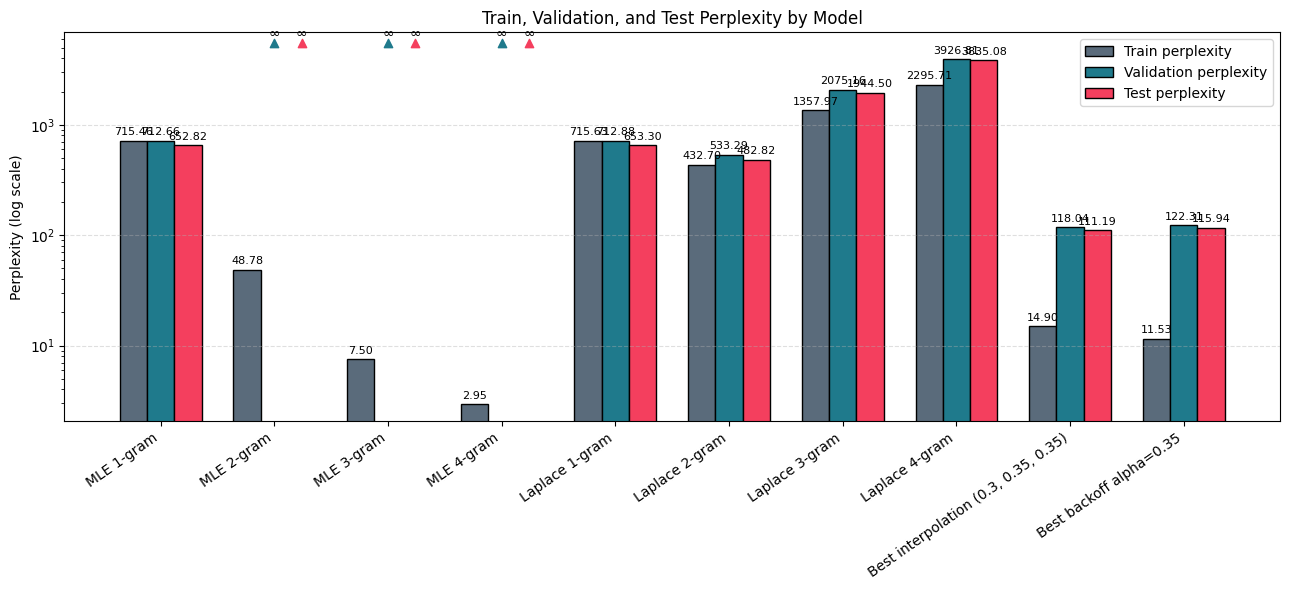

In [109]:
plot_df = perplexity_table.copy()
metric_columns = [
    "Train perplexity",
    "Validation perplexity",
    "Test perplexity",
]
model_labels = plot_df["Model"].tolist()
x = np.arange(len(model_labels))
bar_width = 0.24
colors = ["#5A6B7B", "#1F7A8C", "#F43F5E"]

values = plot_df[metric_columns].to_numpy(dtype=float)
finite_values = values[np.isfinite(values) & (values > 0)]

if finite_values.size == 0:
    print("No finite positive perplexity values to plot.")
else:
    infinity_y = finite_values.max() * 1.4
    fig, ax = plt.subplots(figsize=(13, 6))

    for column_index, (column, color) in enumerate(zip(metric_columns, colors)):
        offset = (column_index - (len(metric_columns) - 1) / 2) * bar_width
        column_values = values[:, column_index]
        bar_heights = np.where(
            np.isfinite(column_values) & (column_values > 0),
            column_values,
            np.nan,
        )

        bars = ax.bar(
            x + offset,
            bar_heights,
            bar_width,
            label=column,
            color=color,
            edgecolor="black",
        )

        for bar, value in zip(bars, column_values):
            bar_x = bar.get_x() + bar.get_width() / 2

            if np.isfinite(value) and value > 0:
                ax.annotate(
                    f"{value:.2f}",
                    (bar_x, value),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha="center",
                    fontsize=8,
                )
            elif np.isinf(value):
                ax.scatter(bar_x, infinity_y, marker="^", color=color, zorder=3)
                ax.annotate(
                    "∞",
                    (bar_x, infinity_y),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha="center",
                )

    ax.set_yscale("log")
    ax.set_ylim(finite_values.min() * 0.7, infinity_y * 1.25)
    ax.set_xticks(x)
    ax.set_xticklabels(model_labels, rotation=35, ha="right")
    ax.set_ylabel("Perplexity (log scale)")
    ax.set_title("Train, Validation, and Test Perplexity by Model")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend()
    fig.tight_layout()
    plt.show()

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۵</b>
<br><br>

در این قسمت نتابج بهترین مدل‌های آموزش دیده محاسبه شد.

موردی که از نمودار بالا مشاهده می‌شود این است که مدل‌های interpolation, backoff ظاهرا دچار overfitting شده‌اند. چون پرپلکسیتی آن‌ها روی داده آموزش بسیار کمتر از تست است ولی دیگر مدل‌ها چنین اختلافی بین ترین و تست دیده نمی‌شود.

همچنین پرپلکسیتی مدل‌های بدون Smooth روی تست بی‌نهایت شده است چون احتمالا ترکیبی را دیده که قبلا در آموزش ندیده بوده.

</div>

<div dir="rtl" align="right">

### ۲.۶ تولید متن از بهترین مدل (۵ نمره)

**صورت مسئله**

یکی از کاربردهای مدل‌های زبانی، تولید متن است. در این زیربخش، از بهترین مدل (کم‌ترین perplexity روی test) برای تولید چند جمله‌ی نمونه استفاده می‌کنیم. تولید به‌صورت تدریجی و با نمونه‌گیری وزن‌دار از توزیع احتمال انجام می‌شود.

**آنچه باید انجام دهید**

- بهترین مدل را بر اساس perplexity مشخص کنید.
- یک تابع تولید متن پیاده‌سازی کنید که از توزیع احتمال مدل، توکن بعدی را نمونه‌گیری کند.
- حداقل ۵ جمله با سه دمای مختلف (مثلاً T=0.5، ۱، ۱.۵) تولید کنید و تفاوت کیفیت را تحلیل کنید و تاثیر دما در تولید متن را بیان کنید.

</div>

$$
P_T(w \mid h) =
\frac{P(w \mid h)^{1/T}}
{\sum_{v \in V} P(v \mid h)^{1/T}}
$$

In [105]:

import math
import random


class SamplingNGram:
    def __init__(self, model):
        # Wrap an existing trained model without modifying it.
        self.model = model

    def inference(self, sentence, max_new_tokens=30, temperature=1.0):
        if temperature <= 0:
            raise ValueError("temperature must be > 0")

        model = self.model
        tokenizer = model.tokenizer
        unk_id = tokenizer.token_to_id("<unk>")

        # Encode and preserve the original prompt.
        tokens = tokenizer.encode(
            sentence, add_special_tokens=False
        ).ids

        generated = tokens.copy()

        # Replace unseen tokens only in the prediction context.
        context_tokens = [
            token_id if token_id in model.observed_token_ids else unk_id
            for token_id in tokens
        ]

        # Use the prediction vocabulary for smoothed models.
        if hasattr(model, "vocab_ids"):
            vocab = set(model.vocab_ids)
        else:
            vocab = {
                gram[-1] for gram in model.ngram_counts
            }

        # Exclude unknown and beginning-of-sentence tokens.
        vocab.discard(unk_id)
        vocab.discard(model.bos_id)
        vocab = sorted(vocab)

        for _ in range(max_new_tokens):
            if model.n == 1:
                context = ()
            else:
                padded = (
                    [model.bos_id] * (model.n - 1)
                    + context_tokens
                )
                context = tuple(padded[-(model.n - 1):])

            # Calculate next-token probabilities.
            probabilities = [
                model.prob(context + (token_id,))
                for token_id in vocab
            ]

            # Temperature scaling in log space for stability.
            log_weights = [
                math.log(p) / temperature if p > 0
                else -math.inf
                for p in probabilities
            ]

            largest = max(log_weights)

            if largest == -math.inf:
                break  # No possible continuation

            weights = [
                math.exp(w - largest)
                for w in log_weights
            ]

            # Sample proportionally to temperature-adjusted weights.
            next_token = random.choices(
                vocab, weights=weights, k=1
            )[0]

            if next_token == model.eos_id:
                break

            generated.append(next_token)
            context_tokens.append(next_token)
        else:
            print("Warning: max_new_tokens exceeded")

        return tokenizer.decode(
            generated, skip_special_tokens=True
        )


In [106]:
interp_sampler = SamplingNGram(interpolation)

for temperature in np.arange(0.2, 2.01, 0.2):
    print("-" * 50)
    print(
        f"temp {temperature:.1f}: "
        f"{interp_sampler.inference('the company', temperature=temperature)}"
    )

print("-" * 50)

--------------------------------------------------
temp 0.2: the company said
--------------------------------------------------
temp 0.4: the company said
--------------------------------------------------
temp 0.6: the company said it was a  the
--------------------------------------------------
temp 0.8: the company said
--------------------------------------------------
temp 1.0: the company attributed with a issue june have bill and has n issue ended bill permitting would commentconduct linked general electric the contract reop futures trading has
--------------------------------------------------
temp 1.2: the company which u. value remains sub points points of into at wash continued below year du keating to require a member of a toward dollar rebounded later an raiseult
--------------------------------------------------
temp 1.4: the company controlled also incentive and lift quickly bank  absorbyale market division million computersierra pacific nyselong thinking withdrew purch

In [107]:
interp_sampler = SamplingNGram(interpolation)

for temperature in np.arange(0.2, 2.01, 0.2):
    print("-" * 50)
    print(
        f"temp {temperature:.1f}: "
        f"{interp_sampler.inference('I saw a cat in the park and pet it but', temperature=temperature)}"
    )

print("-" * 50)

--------------------------------------------------
temp 0.2: i saw a cat in the park and pet it but georgia-pacific 's 
--------------------------------------------------
temp 0.4: i saw a cat in the park and pet it but if for any  $ n million
--------------------------------------------------
temp 0.6: i saw a cat in the park and pet it but if handled the  the  of the ink
--------------------------------------------------
temp 0.8: i saw a cat in the park and pet it but new jersey wastewater treatment national  interest n n
--------------------------------------------------
temp 1.0: i saw a cat in the park and pet it but is wrong tree because it following disclosure last thing a recession that these buildings that date
--------------------------------------------------
temp 1.2: i saw a cat in the park and pet it but resumed tur as probably act for permission
--------------------------------------------------
temp 1.4: i saw a cat in the park and pet it but not protect athlet as few 

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۶</b>
<br><br>

در این قسمت یک پیاده‌سازی دوباره برای متد inference انجام شد چون متد قبلی به صورت greedy همیشه بهترین و بالاترین احتمال را انتخاب می‌کرد ولی این تابع جدید با در نظر گرفتن توزیع احتمال به صورت وزن‌دار توکن بعدی را انتخاب می‌کند.

همان طور که در جملات دیده می‌شود، پارامتر دمای کمتر از ۱ باعث شده است تا مدل خیلی وابسته به بیشترین احتمال‌ها و پرتکرارترین توکن‌ها باشد تا آن‌ها را انتخاب کند. ولی وقتی پارامتر دما بالاتر از ۱ رفته، مدل توکن‌های خلاقانه‌تری را انتخاب کرده است. ولی دیده می‌شود وقتی پارامتر دما به ۲ رسیده، توکن‌های انتخابی خیلی به فضای جمله یا حتی کلمه قبلی خود ربطی ندارد.

</div>

<div dir="rtl" align="right">

## منابع و ابزارهای کمکی

هر منبعی که در انجام این تکلیف از آن استفاده کرده‌اید (مقاله، مستندات کتابخانه، مخزن کد، پست وبلاگ) و نیز — مطابق سیاست درس — هرگونه استفاده از ابزارهای هوش مصنوعی مولد را در جدول زیر ذکر کنید. اعلام نکردن منابع و ابزارهای استفاده‌شده، مصداق نقض صداقت علمی است.

| ردیف | منبع یا ابزار                                                                                                                                                                                                                 | محل استفاده (شماره‌ی بخش) | نحوه‌ی استفاده                                                                          |
| ---- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------- | --------------------------------------------------------------------------------------- |
| ۱    | [Medium – Complete Guide to NLP Text Preprocessing](https://medium.com/@themustaphatijani/the-complete-guide-to-nlp-text-preprocessing-tokenization-normalization-stemming-lemmatization-206d6a73f623?utm_source=chatgpt.com) | ۱-۲                       | آشنایی با روش‌های پیش‌پردازش متن، نرمال‌سازی و توکن‌سازی                                |
| ۲    | [Tokenizer Training Guide – Corpus Preparation](https://mbrenndoerfer.com/writing/tokenizer-training-guide-huggingface-custom-nlp/corpus-preparation?utm_source=chatgpt.com#folio-reading)                                    | ۱-۲                       | ایده‌گرفتن برای طراحی مراحل پیش‌پردازش داده‌های متنی                                    |
| ۳    | [GeeksforGeeks – Byte Pair Encoding](https://www.geeksforgeeks.org/nlp/byte-pair-encoding-bpe-in-nlp/?utm_source=chatgpt.com)                                                                                                 | ۱-۳                       | مطالعه الگوریتم BPE و نحوه ادغام جفت‌توکن‌ها                                            |
| ۴    | [Hugging Face – GPT-2 Documentation](https://huggingface.co/docs/transformers/model_doc/gpt2?utm_source=chatgpt.com)                                                                                                          | ۱-۶                       | بررسی مستندات GPT-2 و توکنایزر آن                                                       |
| ۵    | [Hugging Face – GPT-2 Fast Tokenizer Source Code](https://huggingface.co/transformers/v4.8.2/_modules/transformers/models/gpt2/tokenization_gpt2_fast.html?utm_source=chatgpt.com)                                            | ۱-۶                       | بررسی پیاده‌سازی توکنایزر سریع GPT-2                                                    |
| ۶    | [Kaggle – Penn Treebank Dataset](https://www.kaggle.com/datasets/aliakay8/penn-treebank-dataset/data?utm_source=chatgpt.com)                                                                                                  | ۲-۱                       | دریافت مجموعه‌داده Penn Treebank برای آموزش و ارزیابی مدل‌های N-gram                    |
| ۷    | [Hugging Face LLM Course – Acquiring a Corpus](https://huggingface.co/learn/llm-course/en/chapter6/8?utm_source=chatgpt.com#acquiring-a-corpus)                                                                               | ۲-۱                       | یادگیری نحوه آماده‌سازی پیکره و آموزش توکنایزر                                          |
| ۸    | [N-grams, Bigrams & Trigrams – N-gram Language Models](https://mbrenndoerfer.com/writing/n-grams-bigrams-trigrams-text-representation-nlp/n-gram-language-models?utm_source=chatgpt.com#folio-reading)                        | ۲-۲                       | الگوبرداری از ساختار کد و نحوه پیاده‌سازی مدل زبان N-gram                               |
| ۹    | [ChatGPT – گفت‌وگوی حل تمرین](https://chatgpt.com/share/6aef6010-2728-83ed-9086-c3ec54a2ea98?utm_source=chatgpt.com)                                                                                                          | کل نوت‌بوک                | استفاده از هوش مصنوعی برای توضیح مفاهیم، راهنمایی پیاده‌سازی، اشکال‌زدایی و بررسی نتایج |


</div>

<div dir="rtl" align="right">

## چک‌لیست پیش از ارسال

- [ ] جدول مشخصات دانشجو تکمیل شده است.
- [ ] همه‌ی سلول‌های دارای نشانه‌ی `WRITE YOUR CODE HERE` تکمیل شده‌اند.
- [ ] همه‌ی سلول‌های پاسخ تشریحی تکمیل شده و هیچ `{{پاسخ_خود_را_اینجا_بنویسید}}` باقی نمانده است.
- [ ] بخش جمع‌بندی و جدول منابع و ابزارهای کمکی تکمیل شده است.
- [ ] نوت‌بوک با `Restart & Run All` بدون خطا اجرا شده و خروجی همه‌ی سلول‌ها در فایل ذخیره شده است.
- [ ] نام فایل مطابق الگوی `NLP_CA1_{LASTNAME}_{STUDENTID}.ipynb` است.

</div>

---

<div dir="rtl" align="right">

## قوانین تحویل و صداقت علمی

### ۱. مهلت و نحوه‌ی ارسال

- مهلت تحویل: ۹ / ۸ / ۱۴۰۵
- مهلت تحویل با تأخیر: ۱۶ / ۸ / ۱۴۰۵ — با اعمال جریمه‌ی ۱۰٪ به ازای هر روز تأخیر
- فایل ارسالی باید با این قالب نام‌گذاری شود: `NLP_CA1_{LASTNAME}_{STUDENTID}.ipynb`
- تنها فایل نوت‌بوک اجراشده پذیرفته می‌شود. به تکالیفی که به‌صورت کاغذی تحویل داده شوند یا به‌صورت تصویر در سامانه بارگذاری شوند، ترتیب اثری داده نخواهد شد.

### ۲. صداقت علمی

- نوت‌بوک تعداد مشخصی از دانشجویان که به‌صورت تصادفی انتخاب می‌شوند بررسی خواهد شد. این بررسی‌ها اطمینان حاصل می‌کنند که کدی که نوشته‌اید واقعاً پاسخ‌های موجود در نوت‌بوک شما را تولید می‌کند. ارائه‌ی پاسخ‌های درست بدون کدی که آن پاسخ‌ها را تولید کرده باشد، موردی جدی از عدم صداقت علمی محسوب می‌شود.
- بررسی‌های خودکار برای تشخیص سرقت علمی روی نوت‌بوک‌ها انجام می‌شود. کپی کردن کد از دیگران نیز موردی جدی از عدم صداقت علمی است.
- این تکلیف باید به‌صورت تک‌نفره انجام شود و پاسخ‌ها باید نتیجه‌ی فعالیت شخص نویسنده باشد؛ هم‌فکری و نوشتن مشترک تمرین نیز مجاز نیست. در صورت مشاهده‌ی تشابه، نمره‌ی تمرین برای همه‌ی افراد مشارکت‌کننده صفر و موضوع به استاد گزارش می‌شود.

### ۳. کد و گزارش

- همه‌ی کدهای پیوست گزارش باید قابلیت اجرای مجدد داشته باشند. اگر اجرای دوباره به تنظیمات خاصی نیاز دارد، آن تنظیمات را در گزارش ذکر کنید.
- همه‌ی کدها باید توسط خودتان اجرا شده و نتایج اجرا در فایل ارسالی قابل مشاهده باشد. به کدهایی که نتیجه‌ی اجرای آن‌ها در فایل ارسالی مشخص نباشد نمره‌ای تعلق نمی‌گیرد.
- خوانایی گزارش و دقت تحلیل‌ها در نمره‌دهی اهمیت ویژه دارد.

### ۴. پرسش و پاسخ

- پرسش‌های خود درباره‌ی این تکلیف را در گروه بله یا تلگرام یا از طریق ایمیل azerila.farshi@gmail.com مطرح کنید و در ایمیل‌ها حتماً چیف تی‌ای درس (msabour.official@gmail.com) را cc کنید.
